cat qubits, from losing photons to reading a bit

this follows the introductory track, then the standard track of the supplied
duquantum 2026 prompt. the small comments are there so the calculations can be
walked through, not just run. all times below are in microseconds.

the questions i want to keep asking: is this a real cat or just two blobs?
is a small error physical, or did the fock-space ceiling manufacture it?
and can the buffer's ringing help a measurement instead of just delaying it?

the numbers below are computed by these cells, not typed in from the prompt's expectations.

In [1]:
import os  # keep caches local when this runs on another computer
from pathlib import Path  # portable paths for the saved tables and figures
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache" / "matplotlib"))

import time  # records the cost of the numerical checks
import json  # saves a small machine-readable summary at the end
import hashlib  # ties cached full-model runs to the actual matrices and solver settings
import importlib.metadata as metadata  # records exactly which package versions ran
import numpy as np  # ordinary arrays for analysis and plotting
import pandas as pd  # puts the convergence results in readable tables
import matplotlib.pyplot as plt  # makes the figures
import scipy.linalg as la  # dense linear algebra for small verification problems
from scipy.optimize import curve_fit  # fits decay rates rather than eyeballing them
from scipy.sparse.linalg import eigs  # finds slow modes without evolving for seconds
from scipy.integrate import cumulative_trapezoid  # accumulates readout information
from scipy.special import erfc  # gaussian discrimination error, with caveats below
import qutip as qt  # independent sparse solver and wigner-function calculation
import dynamiqs as dq  # the master-equation solver requested in the challenge
import jax  # dynamiqs uses jax underneath
import jax.numpy as jnp  # arrays which the compiled solver understands
from IPython.display import display  # keeps tables readable inside the notebook

dq.set_precision("double")  # tiny decay rates need 64-bit, not the tutorial's 32-bit
dq.set_progress_meter(False)  # a separate progress bar for every solve gets noisy
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
artifacts = Path("artifacts")  # these are generated results, not input data
artifacts.mkdir(exist_ok=True)
g2 = 2 * np.pi * 0.763  # mhz -> angular frequency per microsecond
kb = 2 * np.pi * 2.6  # intentionally leaky buffer
ka = 2 * np.pi * 0.0093  # unwanted single-photon memory loss
alpha = 2.1  # target separation in coherent-state amplitude
k2 = 4 * g2**2 / kb  # eliminated-buffer prediction, not automatically valid
eps_d = g2 * alpha**2  # buffer drive with the sign convention of this prompt
versions = {name: metadata.version(name) for name in ["dynamiqs", "jax", "qutip", "numpy", "scipy", "matplotlib", "pandas"]}
print(versions)
print(f"jax double precision: {jax.config.x64_enabled}; devices: {jax.devices()}")
display(pd.Series({"g2": g2, "kb": kb, "ka": ka, "k2": k2, "eps_d": eps_d}, name="per microsecond"))

{'dynamiqs': '0.3.7', 'jax': '0.12.0.1', 'qutip': '5.3.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'pandas': '3.1.0'}
jax double precision: True; devices: [CpuDevice(id=0)]


g2        4.794070
kb       16.336282
ka        0.058434
k2        5.627501
eps_d    21.141850
Name: per microsecond, dtype: float64

a few reusable pieces, so changing a cutoff really changes the same model.

a density matrix contains populations on its diagonal and coherences off its
diagonal. the two-mode matrix is indexed as `(memory, buffer)` on each side.
tracing out the buffer means summing over its matching row/column indices.
i save the reduced memory state during a solve, rather than hundreds of large
two-mode matrices. this changes storage, not the equation being integrated.

In [2]:
def cat_ket(n, amplitude, sign=1):
    plus = dq.coherent(n, amplitude)  # one well
    minus = dq.coherent(n, -amplitude)  # the other well
    return dq.unit(plus + sign * minus)  # normalization includes their overlap


def two_mode(na, nb, amplitude=alpha, loss=ka, drive=0.0, coupling=g2, buffer_loss=kb):
    a, b = dq.destroy(na, nb)  # tensor-product operators, not two unrelated matrices
    h = coupling * (a @ a @ b.dag() + a.dag() @ a.dag() @ b)
    h = h - coupling * amplitude**2 * (b + b.dag())  # same target wells at every cutoff
    h = h + drive * (a + a.dag())  # optional real resonant memory drive
    jumps = [np.sqrt(buffer_loss) * b, np.sqrt(loss) * a]  # rates belong inside square roots
    tail_a = dq.tensor(dq.fock_dm(na, na - 2) + dq.fock_dm(na, na - 1), dq.eye(nb))
    tail_b = dq.tensor(dq.eye(na), dq.fock_dm(nb, nb - 1))  # include the transient, not only the end
    parity = dq.tensor(dq.parity(na), dq.eye(nb))  # only memory parity is the cat observable
    observables = [a.dag() @ a, b.dag() @ b, a, b, parity, tail_a, tail_b]
    return h, jumps, observables, a, b


def evolve(h, jumps, initial, times, observables, dims=None, rtol=2e-8, atol=2e-10):
    extra = None  # single-mode calculations can simply save their small matrices
    if dims is not None:
        extra = lambda t, rho: dq.to_jax(dq.ptrace(rho, 0))  # keep memory, discard buffer
    result = dq.mesolve(h, jumps, initial, jnp.asarray(times), exp_ops=observables,
                       method=dq.method.Tsit5(rtol=rtol, atol=atol, max_steps=2_000_000),
                       save_states=dims is None, save_extra=extra)  # sparse operators accelerate the rhs
    values = np.asarray(result.expects)  # this also waits for the actual computation to finish
    states = np.asarray(result.extra if dims is not None else dq.to_numpy(result.states))
    return {"t": np.asarray(times), "e": values, "rho": states, "final": result.final_state}


def run_key(h, jumps, initial, times, ops, rtol, atol):
    key = hashlib.sha256(f"memory-ptrace-v1:Tsit5:{rtol}:{atol}:{versions}".encode())
    for value in [h, *jumps, initial, *ops]:
        array = np.asarray(dq.to_numpy(value))  # hash actual operators, not just a descriptive filename
        key.update(str((array.shape, array.dtype)).encode())
        key.update(array.tobytes())
    key.update(np.asarray(times, dtype=np.float64).tobytes())
    folder = artifacts / "checkpoints"
    folder.mkdir(exist_ok=True)
    return folder / f"{key.hexdigest()}.npz"


def save_run(path, run):
    np.savez_compressed(path, t=run["t"], e=run["e"], rho=run["rho"], final=dq.to_numpy(run["final"]))


def full_run(na, nb, times, amplitude=alpha, seed=0.0, even=False, loss=ka, drive=0.0,
             rtol=2e-8, atol=2e-10):
    h, jumps, ops, a, b = two_mode(na, nb, amplitude, loss, drive)  # one model for every experiment
    memory = cat_ket(na, amplitude) if even else dq.coherent(na, seed)
    initial = dq.tensor(memory, dq.fock(nb, 0))  # buffer starts empty
    path = run_key(h, jumps, initial, times, ops, rtol, atol)
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:  # optional speed-up; no pickle or hidden dependencies
            run = {name: saved[name] for name in ["t", "e", "rho"]}
            run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
            return run
    run = evolve(h, jumps, initial, times, ops, (na, nb), rtol, atol)
    save_run(path, run)  # delete artifacts/checkpoints to force every solve to run again
    return run


def checks(run):
    rho = run["rho"]  # reduced states still must be valid density matrices
    trace_error = np.max(np.abs(np.trace(rho, axis1=-2, axis2=-1) - 1))
    herm_error = np.max(np.abs(rho - rho.swapaxes(-1, -2).conj()))
    minimum_eigenvalue = np.linalg.eigvalsh(rho).min()  # negative beyond solver error is a warning
    return {"trace error": trace_error, "hermiticity error": herm_error, "min eigenvalue": minimum_eigenvalue}


def plot_wigners(states, titles, filename):
    grid = np.linspace(-3.8, 3.8, 151)  # axes are real and imaginary coherent amplitude
    fig, axes = plt.subplots(1, len(states), figsize=(3.1 * len(states), 2.8), constrained_layout=True)
    for axis, state, title in zip(np.atleast_1d(axes), states, titles):
        w = qt.wigner(qt.Qobj(state), grid, grid, g=2)  # g=2 means x=real(alpha), p=imag(alpha)
        axis.contourf(grid, grid, w, levels=np.linspace(-2 / np.pi, 2 / np.pi, 65), cmap="RdBu_r", extend="both")
        axis.set(title=title, xlabel="real amplitude", ylabel="imaginary amplitude", aspect="equal")
    fig.savefig(artifacts / filename, bbox_inches="tight")  # the notebook also retains the picture
    plt.show()


def table(frame, name):
    frame.to_csv(artifacts / f"{name}.csv", index=False)  # enough precision for independent replotting
    display(frame)


def finish_figure(fig, name):
    fig.tight_layout()  # don't cut off axis labels
    fig.savefig(artifacts / f"{name}.png", bbox_inches="tight")
    plt.show()

1.0a — one photon at a time

here the whole state stays coherent: its amplitude is
$2\exp[-(\kappa/2+i\Delta)t]$. squaring its magnitude gives the predicted
photon number. this is a useful check on units, normalization, and the solver.

maximum photon-number error: 1.994e-11


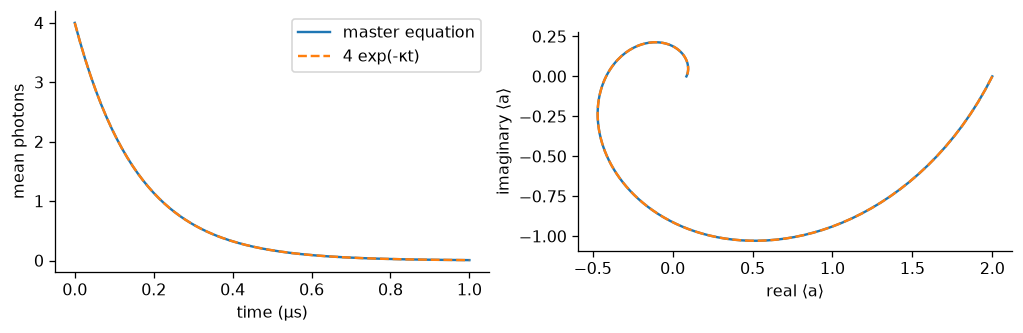

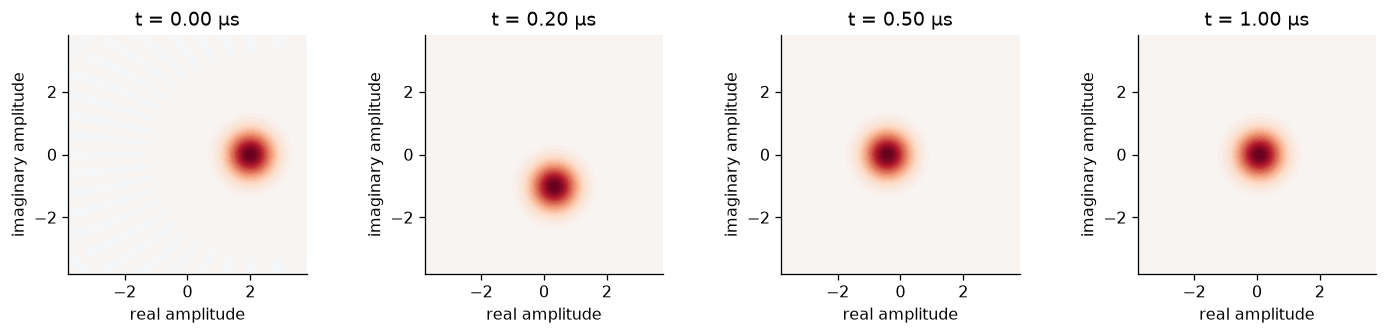

In [3]:
n = 30  # the warm-up cutoff requested in the prompt
c = dq.destroy(n)  # a single memory mode for now
number = c.dag() @ c  # counts photons
warm_t = np.linspace(0, 1, 151)  # one microsecond
warm = evolve(2 * np.pi * number, [np.sqrt(2 * np.pi) * c], dq.coherent(n, 2), warm_t, [number, c])
analytic_n = 4 * np.exp(-2 * np.pi * warm_t)  # the loss rate is angular, as specified
analytic_a = 2 * np.exp(-(np.pi + 2j * np.pi) * warm_t)  # rotating and shrinking
warm_error = np.max(np.abs(warm["e"][0].real - analytic_n))
print(f"maximum photon-number error: {warm_error:.3e}")
assert warm_error < 2e-6  # fail visibly if an elementary case is wrong
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(warm_t, warm["e"][0].real, label="master equation")
axes[0].plot(warm_t, analytic_n, "--", label="4 exp(-κt)")
axes[0].set(xlabel="time (μs)", ylabel="mean photons")
axes[0].legend()
axes[1].plot(warm["e"][1].real, warm["e"][1].imag, label="simulation")
axes[1].plot(analytic_a.real, analytic_a.imag, "--", label="analytic amplitude")
axes[1].set(xlabel="real ⟨a⟩", ylabel="imaginary ⟨a⟩", aspect="equal")
finish_figure(fig, "01_single_photon_loss")
plot_wigners(warm["rho"][[0, 30, 75, 150]], [f"t = {warm_t[i]:.2f} μs" for i in [0, 30, 75, 150]], "02_shrinking_coherent.png")

1.0b — losing pairs leaves an odd photon behind

$a^2$ annihilates both $|0\rangle$ and $|1\rangle$. more importantly, it never
changes even/odd parity. every initially odd fock population can cascade down
to $|1\rangle$, not just the population that started there. so the limiting
photon number is the *total initial odd probability*,
$(1-e^{-2|\alpha_0|^2})/2$, not $P(n=1)$.

final n = 0.499832269; total odd probability = 0.499832269


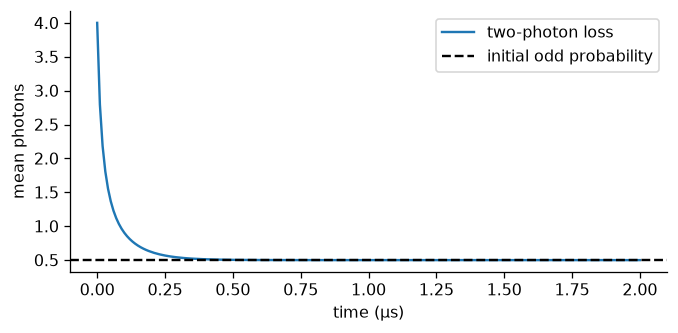

In [4]:
pair_t = np.linspace(0, 2, 201)  # enough time for all higher fock levels to empty
pair = evolve(0 * number, [np.sqrt(k2) * c @ c], dq.coherent(n, 2), pair_t, [number, dq.parity(n)])
odd_probability = (1 - np.exp(-8)) / 2  # coherent-state poisson distribution, summed over odd n
print(f"final n = {pair['e'][0, -1].real:.9f}; total odd probability = {odd_probability:.9f}")
assert abs(pair["e"][0, -1].real - odd_probability) < 2e-6
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(pair_t, pair["e"][0].real, label="two-photon loss")
ax.axhline(odd_probability, ls="--", color="black", label="initial odd probability")
ax.set(xlabel="time (μs)", ylabel="mean photons")
ax.legend()
finish_figure(fig, "03_pair_loss")

1.0c — add the drive inside the two-photon jump

if $\kappa_a=0$, multiplying $\kappa_2$ multiplies the *entire* generator, so
changing $\kappa_2$ is exactly rescaling time. with fixed nonzero $\kappa_a$,
that statement is only approximate, and the final photon numbers can differ
slightly too. the steady state is not exactly a pure even cat under loss.

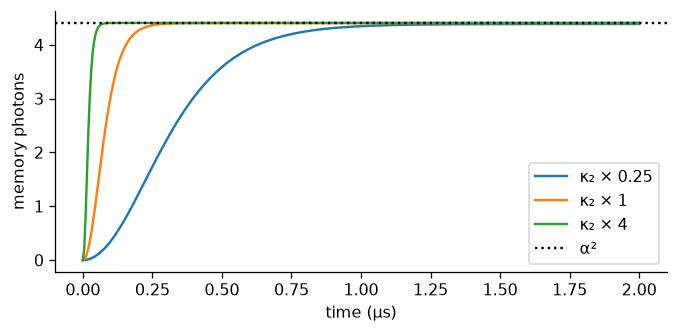

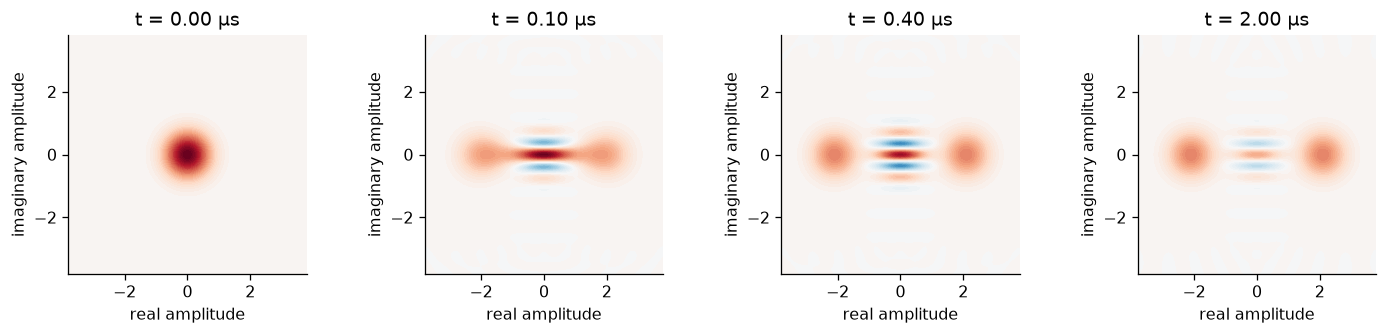

In [5]:
inflate_t = np.linspace(0, 2, 401)  # resolves the early overshoot in the next task too
effective = {}  # keep all three runs for later comparisons
for factor in [0.25, 1.0, 4.0]:
    l2 = np.sqrt(factor * k2) * (c @ c - alpha**2 * dq.eye(n))
    effective[factor] = evolve(0 * number, [l2, np.sqrt(ka) * c], dq.fock(n, 0), inflate_t, [number, dq.parity(n)])
fig, ax = plt.subplots(figsize=(6, 3))
for factor, run in effective.items():
    ax.plot(inflate_t, run["e"][0].real, label=f"κ₂ × {factor:g}")
ax.axhline(alpha**2, ls=":", color="black", label="α²")
ax.set(xlabel="time (μs)", ylabel="memory photons")
ax.legend()
finish_figure(fig, "04_effective_stabilization")
plot_wigners(effective[1.0]["rho"][[0, 20, 80, 400]], [f"t = {inflate_t[i]:.2f} μs" for i in [0, 20, 80, 400]], "05_effective_cat.png")

1.1 and 1.2 — let the buffer be a real mode, and move both ceilings

the workshop hint was to vary the memory hilbert-space truncation too.
here each axis is swept separately. a tiny final buffer occupation does not
excuse cutting off its earlier transient. the reference is the largest tested
pair, not a claim to have simulated an infinite oscillator.

the declared observable tolerance is 0.2% relative to that reference, for both
final photon number and transient peak. tails are a separate diagnostic:
a small tail alone is not a convergence proof. a 0.005 μs output grid locates
the peak; a finer-grid check below tests that choice.

In [6]:
cutoff_pairs = [(na, 12) for na in [16, 20, 24, 32, 40]]  # memory sweep with buffer held fixed
cutoff_pairs += [(40, nb) for nb in [4, 6, 8, 10, 16]]  # buffer sweep; (40,12) already exists
cutoff_pairs += [(24, 6)]  # the suggested starting point deserves a direct comparison
inflations = {}  # keep reduced states, not all the large joint density matrices
cutoff_rows = []
for na, nb in cutoff_pairs:
    start = time.perf_counter()  # includes compilation when this dimension is new
    run = full_run(na, nb, inflate_t)
    inflations[na, nb] = run
    cutoff_rows.append({"na": na, "nb": nb, "final n": run["e"][0, -1].real,
                        "peak n": run["e"][0].real.max(), "peak buffer n": run["e"][1].real.max(),
                        "max memory tail": run["e"][5].real.max(), "max buffer tail": run["e"][6].real.max(),
                        "seconds": time.perf_counter() - start})
    print(f"cutoffs ({na}, {nb}) finished in {cutoff_rows[-1]['seconds']:.1f}s", flush=True)
convergence = pd.DataFrame(cutoff_rows)
reference_row = convergence.query("na == 40 and nb == 16").iloc[0]
for quantity in ["final n", "peak n"]:
    convergence[f"relative error: {quantity}"] = abs(convergence[quantity] / reference_row[quantity] - 1)
table(convergence, "cutoff_convergence")
observable_tolerance = 0.002  # 0.2%, stated before selecting a cutoff
for column, fixed_column, fixed_value in [("na", "nb", 12), ("nb", "na", 40)]:
    subset = convergence[convergence[fixed_column] == fixed_value].sort_values(column)
    for quantity in ["final n", "peak n"]:
        passing = subset[f"relative error: {quantity}"].to_numpy() < observable_tolerance
        stable = np.logical_and.accumulate(passing[::-1])[::-1]  # every larger tested value must pass too
        print(f"smallest tested {column} passing {quantity}: {subset.loc[stable, column].min()}")

cutoffs (16, 12) finished in 3.6s


cutoffs (20, 12) finished in 2.9s


cutoffs (24, 12) finished in 3.0s


cutoffs (32, 12) finished in 3.0s


cutoffs (40, 12) finished in 3.0s


...

cutoffs (40, 10) finished in 2.3s


cutoffs (40, 16) finished in 1.9s


cutoffs (24, 6) finished in 1.9s


,na,nb,final n,peak n,peak buffer n,max memory tail,max buffer tail,seconds,relative error: final n,relative error: peak n
0,16,12,4.407074,6.373158,1.996227,5.712957e-02,0.003595,3.595337,1.162128e-03,0.077840
1,20,12,4.402086,6.807557,1.992262,1.259750e-02,0.001286,2.906988,2.894579e-05,0.014985
2,24,12,4.401970,6.896737,1.991880,2.000029e-03,0.000385,2.972100,2.485057e-06,0.002081
3,32,12,4.401958,6.908426,1.991853,1.364555e-05,0.000169,3.035579,2.495303e-07,0.000390
4,40,12,4.401958,6.908440,1.991853,3.303086e-07,0.000169,3.013224,2.108464e-07,0.000387
5,40,4,4.402302,4.462028,1.487084,1.916149e-08,0.193312,2.382408,7.799770e-05,0.354370
6,40,6,4.402091,6.114285,1.889598,7.172523e-09,0.046242,0.998878,3.014314e-05,0.115297
7,40,8,4.401975,6.744151,1.980652,3.087124e-07,0.008641,2.335351,3.794704e-06,0.024159
8,40,10,4.401958,6.886450,1.990910,2.631637e-07,0.001326,2.347550,2.230506e-07,0.003569
9,40,16,4.401959,6.911117,1.991905,4.535692e-07,0.000002,1.918853,0.000000e+00,0.000000


smallest tested na passing final n: 16
smallest tested na passing peak n: 32
smallest tested nb passing final n: 4
smallest tested nb passing peak n: 12


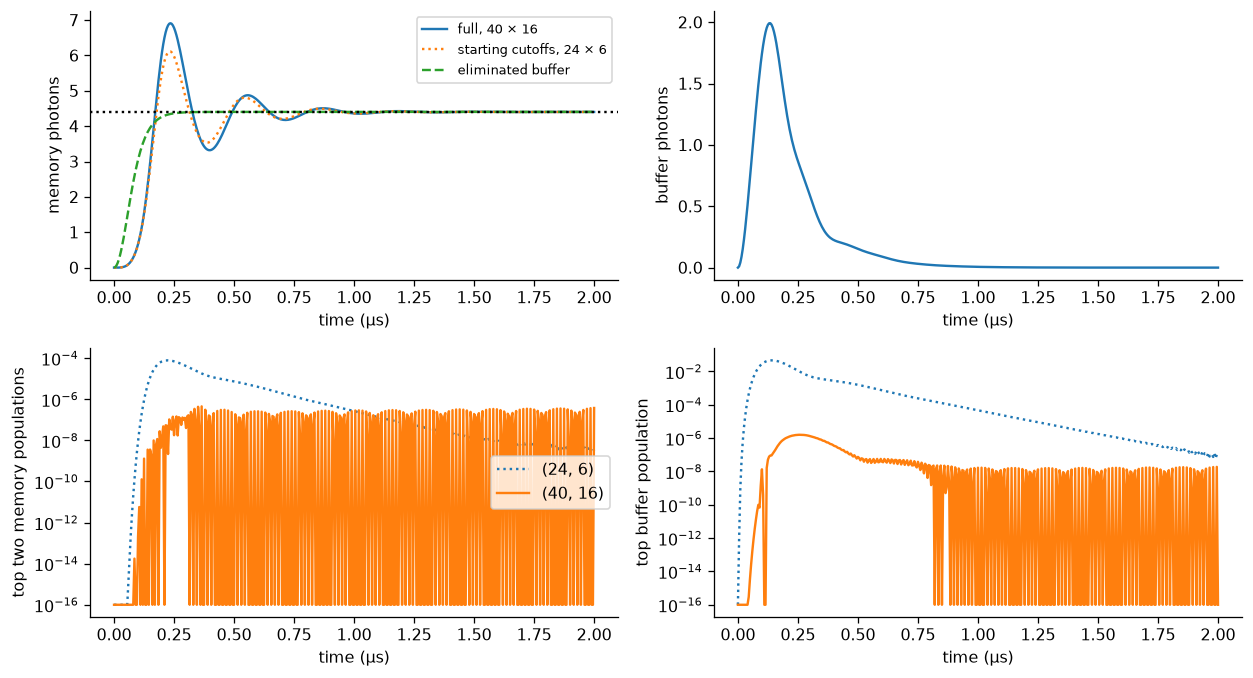

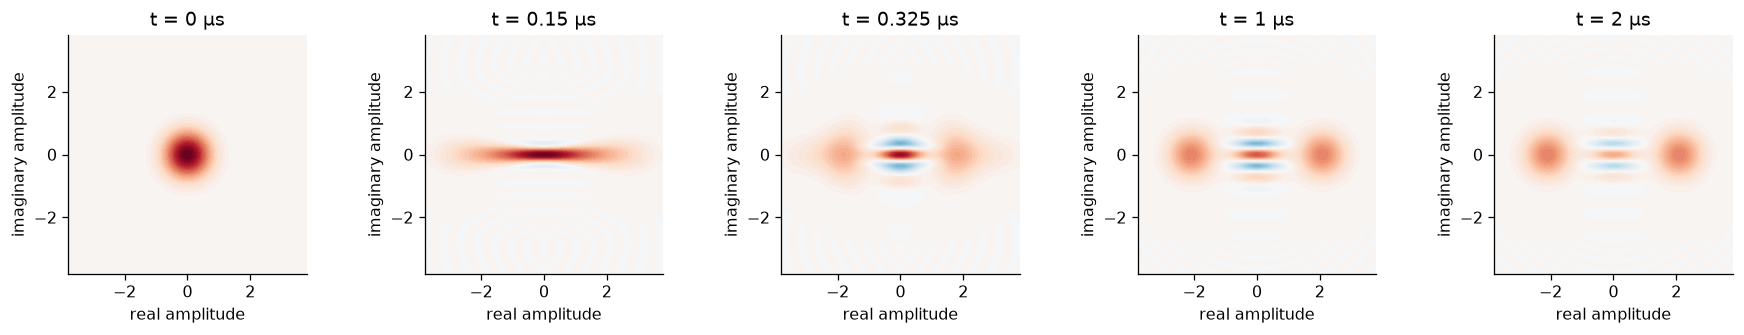

g2/kb = 0.2935; eps_d/kb = 1.2942
final n differs from alpha² by -0.182%
reference reduced-state checks: {'trace error': np.float64(1.9984014443252818e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.742935356532031e-06)}


In [7]:
inflation = inflations[40, 16]  # safest tested run for figures and cat-state diagnostics
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].plot(inflate_t, inflation["e"][0].real, label="full, 40 × 16")
axes[0, 0].plot(inflate_t, inflations[24, 6]["e"][0].real, ":", label="starting cutoffs, 24 × 6")
axes[0, 0].plot(inflate_t, effective[1.0]["e"][0].real, "--", label="eliminated buffer")
axes[0, 0].axhline(alpha**2, ls=":", color="black")
axes[0, 0].set(ylabel="memory photons")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(inflate_t, inflation["e"][1].real)
axes[0, 1].set(ylabel="buffer photons")
for pair, style in [((24, 6), ":"), ((40, 16), "-")]:
    run = inflations[pair]
    axes[1, 0].semilogy(inflate_t, np.maximum(run["e"][5].real, 1e-16), style, label=str(pair))
    axes[1, 1].semilogy(inflate_t, np.maximum(run["e"][6].real, 1e-16), style, label=str(pair))
axes[1, 0].set(ylabel="top two memory populations")
axes[1, 1].set(ylabel="top buffer population")
for axis in axes.flat:
    axis.set(xlabel="time (μs)")
axes[1, 0].legend()
finish_figure(fig, "06_full_inflation_and_tails")
plot_wigners(inflation["rho"][[0, 30, 65, 200, 400]], [f"t = {inflate_t[i]:.3g} μs" for i in [0, 30, 65, 200, 400]], "07_full_cat.png")
print(f"g2/kb = {g2/kb:.4f}; eps_d/kb = {eps_d/kb:.4f}")
print(f"final n differs from alpha² by {100*(inflation['e'][0,-1].real/alpha**2-1):.3f}%")
print("reference reduced-state checks:", checks(inflation))
assert abs(inflation["e"][0, -1].real / alpha**2 - 1) < 0.02
assert checks(inflation)["trace error"] < 1e-7

the eliminated-buffer assumptions are not satisfied: $g_2/\kappa_b\simeq0.293$
and $\epsilon_d/\kappa_b\simeq1.294$. the buffer stores excitation and feeds it
back before it leaks away. linearizing near either well gives poles

$$\lambda_\pm=-\kappa_b/4\pm\sqrt{(\kappa_b/4)^2-(2g_2\alpha)^2}.$$

these are complex here: ringing is physical. also, with memory loss the
semiclassical stationary value is $|a|^2=\alpha^2-\kappa_a\kappa_b/(8g_2^2)$,
not precisely $\alpha^2$. settling of photon number is not settling of parity.

In [8]:
fine = full_run(32, 12, np.linspace(0, 2, 801), rtol=4e-9, atol=4e-11)  # tighter tolerance and twice the output resolution
coarse = inflations[32, 12]
print(f"peak change with tighter integration/finer output: {abs(fine['e'][0].real.max()-coarse['e'][0].real.max()):.3e}")
print(f"maximum matched-time n change: {np.max(abs(fine['e'][0, ::2]-coarse['e'][0])):.3e}")
late = inflate_t >= 1.5  # check an interval, not just the last point
print(f"late-time n variation / alpha²: {np.ptp(inflation['e'][0, late].real)/alpha**2:.3e}")
print(f"semiclassical loss-corrected n: {alpha**2-ka*kb/(8*g2**2):.6f}")

peak change with tighter integration/finer output: 8.762e-09
maximum matched-time n change: 9.021e-08
late-time n variation / alpha²: 1.803e-03
semiclassical loss-corrected n: 4.404808


1.3 — what state did inflation actually make?

$[P,H]=0$ and the buffer jump commutes with memory parity, but $Pa=-aP$.
without memory loss, vacuum's even parity stays even. with memory loss,
$d\langle P\rangle/dt=-2\kappa_a\langle n_aP\rangle$; it is not conserved.

i use squared pure-state fidelity $F_+=\langle C_+|\rho_a|C_+\rangle$.
the equal incoherent mixture of the two coherent states has parity
$e^{-2\alpha^2}$ and $F_+=(1+e^{-2\alpha^2})/2$. exceeding those baselines,
together with the negative central wigner fringes, distinguishes coherence
from merely seeing two lobes. there is no sharp universal 'cat lifetime'.

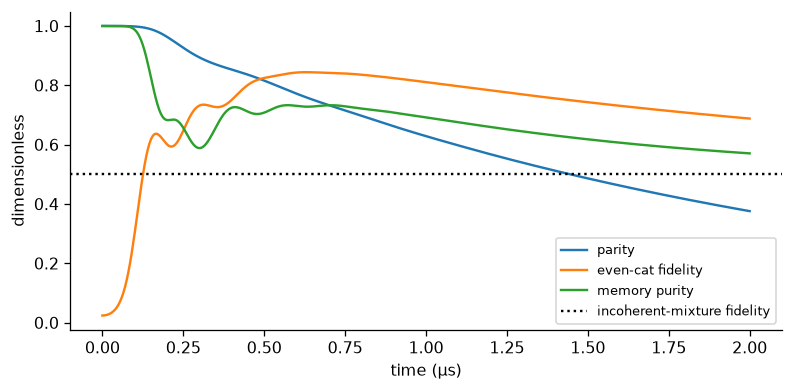

best even-cat fidelity = 0.844302 at t = 0.630 μs


prepared-cat parity 1/e time: 1.960 μs; simple prediction: 1.940 μs


maximum parity drift with ka=0: 1.998e-15


In [9]:
even40 = np.asarray(dq.to_numpy(cat_ket(40, alpha))).ravel()
cat_fidelity = np.einsum("i,tij,j->t", even40.conj(), inflation["rho"], even40).real
purity = np.einsum("tij,tji->t", inflation["rho"], inflation["rho"]).real
mixture_fidelity = (1 + np.exp(-2 * alpha**2)) / 2
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(inflate_t, inflation["e"][4].real, label="parity")
ax.plot(inflate_t, cat_fidelity, label="even-cat fidelity")
ax.plot(inflate_t, purity, label="memory purity")
ax.axhline(mixture_fidelity, ls=":", color="black", label="incoherent-mixture fidelity")
ax.set(xlabel="time (μs)", ylabel="dimensionless")
ax.legend(fontsize=8)
finish_figure(fig, "08_which_cat")
best_cat_index = int(np.argmax(cat_fidelity))
print(f"best even-cat fidelity = {cat_fidelity[best_cat_index]:.6f} at t = {inflate_t[best_cat_index]:.3f} μs")
coherence_t = np.linspace(0, 8, 401)  # long enough to cross an explicit 1/e coherence threshold
long_cat = full_run(28, 6, coherence_t, even=True)  # start from a prepared cat to isolate its lifetime
baseline_parity = np.exp(-2 * alpha**2)
crossings = np.flatnonzero(long_cat["e"][4].real - baseline_parity < (1-baseline_parity)/np.e)
print(f"prepared-cat parity 1/e time: {coherence_t[crossings[0]]:.3f} μs; simple prediction: {1/(2*ka*alpha**2):.3f} μs")
zero_loss = full_run(28, 10, inflate_t, loss=0.0)  # remove only the term that breaks parity
print(f"maximum parity drift with ka=0: {np.max(abs(zero_loss['e'][4]-1)):.3e}")
assert np.max(abs(zero_loss["e"][4] - 1)) < 1e-7

for a definite logical bit, a coherent seed breaks the sign symmetry *before*
inflation. this is not just initializing the final target: the seed sweep
below starts with amplitudes below 2.1 and lets the same stabilizer grow them.
the cost is a calibrated, phase-referenced memory displacement pulse (and its
control port), not measurement postselection. the seed preparation itself is
idealized as an instantaneous displacement here.

,seed amplitude,initial photons,final real a,final fidelity to +alpha
0,0.0,0.00,0.000000,0.500020
1,0.5,0.25,1.441737,0.843560
2,1.0,1.00,2.007259,0.978297
3,1.5,2.25,2.093251,0.998781


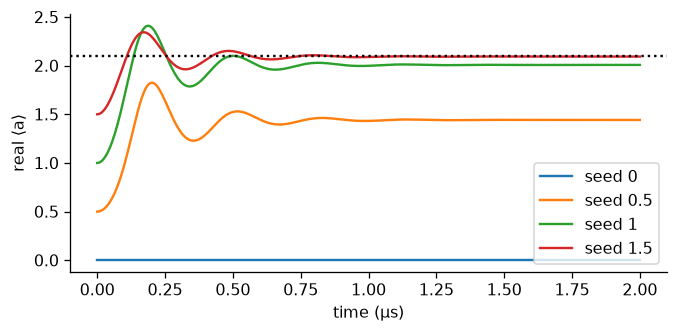

In [10]:
seed_rows = []
seed_runs = {}
target28 = np.asarray(dq.to_numpy(dq.coherent(28, alpha))).ravel()
for seed in [0.0, 0.5, 1.0, 1.5]:
    run = full_run(28, 10, inflate_t, seed=seed)
    seed_runs[seed] = run
    final_f = np.vdot(target28, run["rho"][-1] @ target28).real  # no square root convention ambiguity
    seed_rows.append({"seed amplitude": seed, "initial photons": seed**2,
                      "final real a": run["e"][2, -1].real, "final fidelity to +alpha": final_f})
table(pd.DataFrame(seed_rows), "logical_state_preparation")
fig, ax = plt.subplots(figsize=(6, 3))
for seed, run in seed_runs.items():
    ax.plot(inflate_t, run["e"][2].real, label=f"seed {seed:g}")
ax.axhline(alpha, color="black", ls=":")
ax.set(xlabel="time (μs)", ylabel="real ⟨a⟩")
ax.legend()
finish_figure(fig, "09_seeded_preparation")

2.1 — measure a slow bit decay, without mistaking it for a numerical floor

the prompt calls the decay of $\mathrm{Re}\langle a\rangle$ $\Gamma_X$.
a symmetric classical bit with single-event rate $r$ has imbalance
$e^{-2rt}$, so the prompt's $\Gamma_X=2r$. several papers quote $r$ instead.
the same factor-of-two issue appears for parity and phase flips.

short-time physics uses dynamiqs. for the very long, stiff small-cat decays i
also use qutip's sparse master-equation solver, with the *same* matrices, and
compare the fitted rates to slow eigenvalues of the full two-mode generator.
this is not adiabatic elimination. a spectral residual, cutoff changes, and
fit-window changes are reported; a pretty straight line is not enough.

In [11]:
def sparse_model(na, nb, amplitude, drive=0.0):
    h, jumps, ops, _, _ = two_mode(na, nb, amplitude, drive=drive)
    dims = [[na, nb], [na, nb]]  # keep tensor information for partial traces
    convert = lambda op: qt.Qobj(dq.to_numpy(op), dims=dims).to("csr")
    return convert(h), [convert(op) for op in jumps], [convert(op) for op in ops]


def slow_bit_mode(na, nb, amplitude, drive=0.0):
    h, jumps, ops = sparse_model(na, nb, amplitude, drive)
    generator = qt.liouvillian(h, jumps).data.as_scipy().tocsc()  # d² by d², but sparse
    vals, vecs = eigs(generator, k=6, sigma=1e-6, tol=1e-10, v0=np.ones(generator.shape[0], dtype=complex))
    d = na * nb
    candidates = []
    for i, value in enumerate(vals):
        rho_mode = vecs[:, i].reshape((d, d), order="F")  # qutip stacks columns
        trace = abs(np.trace(rho_mode))  # stationary mode has nonzero trace; decay modes do not
        overlap = abs(np.trace(ops[2].full() @ rho_mode))  # does this mode actually change the logical bit?
        if trace < 1e-4 and overlap > 1e-3 and value.real < -1e-12:
            candidates.append((value.real, i, overlap))
    if not candidates:
        raise RuntimeError("no resolved bit mode; enlarge the spectral search or precision")
    _, index, overlap = max(candidates)  # slowest decaying mode visible to a
    value = vals[index]
    residual = np.linalg.norm(generator @ vecs[:, index] - value * vecs[:, index])
    return {"rate": -value.real, "imaginary part": value.imag, "residual": residual, "a overlap": overlap}


def fit_decay(times, signal, start=0.0, offset=False):
    keep = np.asarray(times) >= start  # discard the fast adjustment to the metastable manifold
    t = np.asarray(times)[keep]
    y = np.asarray(signal).real[keep]
    scale_t = t[-1] - t[0]  # scale time so the optimizer handles very slow rates well
    x = (t - t[0]) / scale_t
    if offset:
        model = lambda x, amp, decay, floor: amp * np.exp(-decay * x) + floor
        guess = [y[0] - y[-1], 2.0, y[-1]]
        bounds = ([-2, 0, -1], [2, 100, 1])
    else:
        model = lambda x, amp, decay: amp * np.exp(-decay * x)
        guess = [y[0], 1.0]
        bounds = ([-10, 0], [10, 100])
    parameters, covariance = curve_fit(model, x, y, p0=guess, bounds=bounds, maxfev=20000, xtol=1e-12, ftol=1e-12, gtol=1e-12)
    prediction = model(x, *parameters)
    return {"rate": parameters[1] / scale_t, "rmse": np.sqrt(np.mean((prediction - y)**2)),
            "floor": parameters[2] if offset else 0.0, "fit t": t, "fit y": prediction}


def sparse_decay(na, nb, amplitude, times):
    h, jumps, ops = sparse_model(na, nb, amplitude)
    initial = qt.tensor(qt.coherent(na, amplitude), qt.basis(nb, 0))
    result = qt.mesolve(h, initial, times, jumps, e_ops=ops,
                       options={"method": "bdf", "rtol": 2e-8, "atol": 2e-10,
                                "nsteps": 2_000_000, "store_states": False})
    return np.asarray(result.expect)  # includes tails over the entire long run

alpha=0.6, fitted Γx=0.0132034/μs


alpha=0.8, fitted Γx=0.00642262/μs


alpha=1.0, fitted Γx=0.00230058/μs


alpha=1.2, fitted Γx=0.00059969/μs


alpha=1.4, fitted Γx=0.000119916/μs


,alpha,alpha²,fit rate,spectral rate,larger cutoff rate,fit rmse,window relative change,cutoff relative change,spectral residual,observed fraction of lifetime,memory tail,buffer tail
0,0.6,0.36,0.013203,0.013203,0.013203,5.300734e-14,4.085621e-13,1.667983e-08,3.550224e-12,1.320339,9.827247e-09,1.421238e-09
1,0.8,0.64,0.006423,0.006423,0.006423,5.053863e-14,2.944311e-13,1.160699e-06,4.414609e-12,0.642262,5.760691e-10,5.269760e-09
2,1.0,1.00,0.002301,0.002301,0.002301,7.367636e-12,8.256129e-11,3.125411e-05,2.014089e-13,0.230059,1.724726e-10,3.203882e-08
3,1.2,1.44,0.000600,0.000600,0.000600,7.326191e-14,9.103829e-14,4.213806e-04,7.168364e-15,0.059969,1.714535e-10,1.134167e-07
4,1.4,1.96,0.000120,0.000120,0.000120,1.063785e-14,1.406009e-10,2.805662e-03,9.179577e-15,0.011992,8.141938e-10,2.185148e-07


finite-range suppression exponent gamma = 2.9545


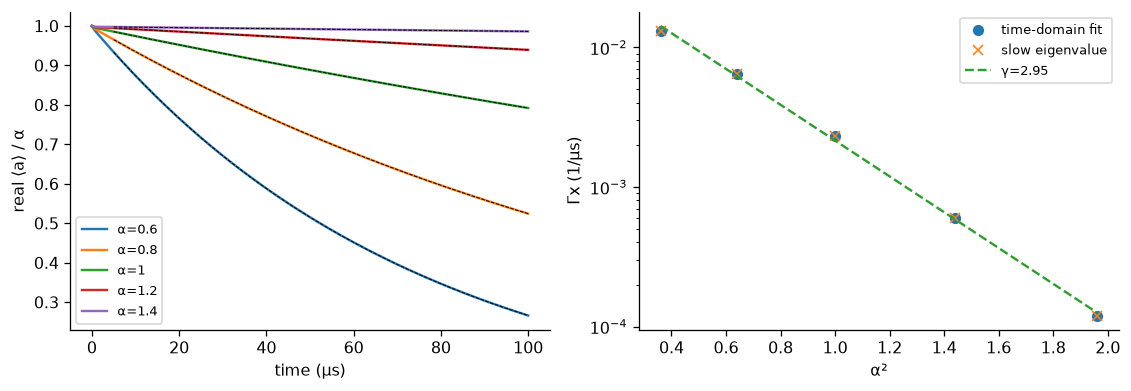

dynamiqs versus qutip: maximum observable difference = 3.302e-06


In [12]:
bit_rows = []
bit_traces = {}
for size in [0.6, 0.8, 1.0, 1.2, 1.4]:
    mode = slow_bit_mode(18, 4, size)  # low buffer occupation here, unlike vacuum inflation
    end = min(100.0, 1.5 / mode["rate"])  # finite early decay is resolvable; don't simulate experimental seconds
    times = np.linspace(0, end, 161)
    signal = sparse_decay(18, 4, size, times)
    fit = fit_decay(times, signal[2].real, start=max(2.0, 0.05 * end))
    later = fit_decay(times, signal[2].real, start=0.3 * end)  # test sensitivity to the fitting window
    check_mode = slow_bit_mode(22, 5, size)  # rates, not only photon numbers, need cutoff tests
    bit_rows.append({"alpha": size, "alpha²": size**2, "fit rate": fit["rate"], "spectral rate": mode["rate"],
                     "larger cutoff rate": check_mode["rate"], "fit rmse": fit["rmse"],
                     "window relative change": abs(later["rate"] / fit["rate"] - 1),
                     "cutoff relative change": abs(check_mode["rate"] / mode["rate"] - 1),
                     "spectral residual": mode["residual"], "observed fraction of lifetime": end * mode["rate"],
                     "memory tail": signal[5].real.max(), "buffer tail": signal[6].real.max()})
    bit_traces[size] = (times, signal, fit)
    print(f"alpha={size:.1f}, fitted Γx={fit['rate']:.6g}/μs", flush=True)
bit_table = pd.DataFrame(bit_rows)
table(bit_table, "bit_flip_rates")
log_slope, log_intercept = np.polyfit(bit_table["alpha²"], np.log(bit_table["fit rate"]), 1)
print(f"finite-range suppression exponent gamma = {-log_slope:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for size, (times, signal, fit) in bit_traces.items():
    axes[0].plot(times, signal[2].real / size, label=f"α={size:g}")
    axes[0].plot(fit["fit t"], fit["fit y"] / size, "--", color="black", lw=0.6)
axes[0].set(xlabel="time (μs)", ylabel="real ⟨a⟩ / α")
axes[0].legend(fontsize=8)
axes[1].semilogy(bit_table["alpha²"], bit_table["fit rate"], "o", label="time-domain fit")
axes[1].semilogy(bit_table["alpha²"], bit_table["spectral rate"], "x", label="slow eigenvalue")
axes[1].semilogy(bit_table["alpha²"], np.exp(log_intercept + log_slope * bit_table["alpha²"]), "--", label=f"γ={-log_slope:.2f}")
axes[1].set(xlabel="α²", ylabel="Γx (1/μs)")
axes[1].legend(fontsize=8)
finish_figure(fig, "10_bit_flip_scaling")
cross_t = np.linspace(0, 4, 101)  # independent solver comparison on a common short window
cross_dq = full_run(18, 4, cross_t, amplitude=1.0, seed=1.0)
cross_qt = sparse_decay(18, 4, 1.0, cross_t)
cross_error = np.max(abs(cross_dq["e"] - cross_qt))
print(f"dynamiqs versus qutip: maximum observable difference = {cross_error:.3e}")
assert cross_error < 2e-5

the naive matrix element is
$|\langle-\alpha|a|\alpha\rangle|^2=\alpha^2e^{-4\alpha^2}$.
it ignores excursions outside the code space and the way stabilization
returns that leaked probability. [dubovitskii, 2025](https://arxiv.org/abs/2407.17299)
finds a second-order single-loss contribution proportional to
$(\kappa_a^2/2\kappa_2)e^{-2\alpha^2}$ in the eliminated model's *event-rate*
convention. that term can dominate even without thermal photons.

so neither an exponent of exactly 2 nor a pure exponential over all sizes is
required here. the prefactor, finite fitting interval, and two-mode dynamics
matter. this also corrects the draft prompt's suggestion that zero temperature
alone explains every exponent above 2. the small-cat fit is not an extrapolation
of hardware lifetimes at α=2.1.

2.2 — phase flips are fast enough to watch directly

each lost photon changes parity. approximately independent jumps at rate
$\kappa_a\alpha^2$ give $\Gamma_Z=2\kappa_a\alpha^2$ for the parity decay.
i fit an offset as well: at smaller cats the limiting parity is not exactly
zero. imposing a zero floor there biases the fitted rate.

,alpha,alpha²,fitted Γz,2 ka alpha²,fitted parity floor,fit rmse,memory tail,buffer tail
0,1.2,1.44,0.168535,0.168289,0.114963,7.248898e-07,9.101355e-08,8.338222e-08
1,1.5,2.25,0.262159,0.262951,0.023115,9.662618e-07,1.126569e-07,1.343325e-07
2,1.8,3.24,0.377812,0.378650,0.003239,7.835360e-07,3.689268e-09,1.763217e-07
3,2.1,4.41,0.514557,0.515385,0.000317,9.111685e-07,4.874473e-09,1.292988e-07
4,2.4,5.76,0.672334,0.673155,0.000022,1.117763e-06,4.532535e-09,8.475570e-08


fitted slope 0.116684; predicted 2ka = 0.116867; intercept 1.87e-05


largest-cat Γz cutoff change: 9.332e-07


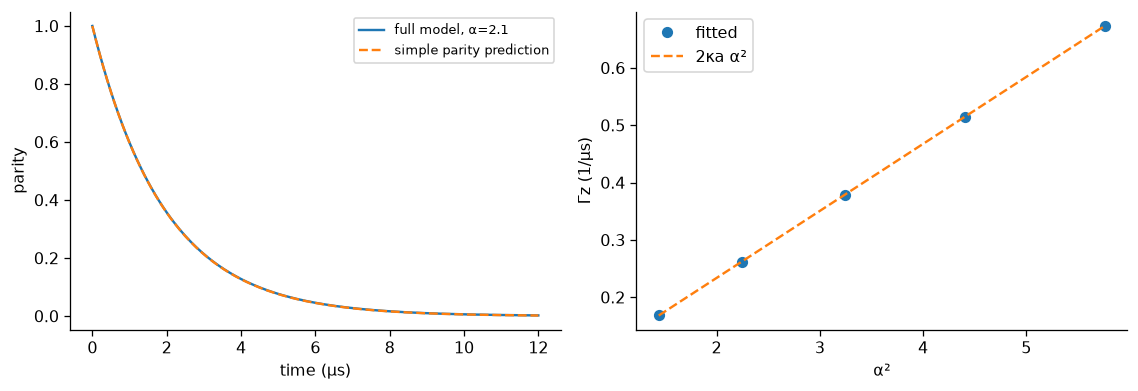

In [13]:
phase_rows = []
phase_traces = {}
phase_t = np.linspace(0, 12, 241)  # includes several lifetimes at the physical target
for size in [1.2, 1.5, 1.8, 2.1, 2.4]:
    run = full_run(32, 5, phase_t, amplitude=size, even=True)
    fit = fit_decay(phase_t, run["e"][4].real, start=0.3, offset=True)
    phase_traces[size] = run
    phase_rows.append({"alpha": size, "alpha²": size**2, "fitted Γz": fit["rate"],
                       "2 ka alpha²": 2 * ka * size**2, "fitted parity floor": fit["floor"],
                       "fit rmse": fit["rmse"], "memory tail": run["e"][5].real.max(),
                       "buffer tail": run["e"][6].real.max()})
phase_table = pd.DataFrame(phase_rows)
table(phase_table, "phase_flip_rates")
phase_slope, phase_intercept = np.polyfit(phase_table["alpha²"], phase_table["fitted Γz"], 1)
print(f"fitted slope {phase_slope:.6f}; predicted 2ka = {2*ka:.6f}; intercept {phase_intercept:.3g}")
phase_check = full_run(36, 7, phase_t, amplitude=2.4, even=True)  # largest cat is the demanding endpoint
phase_check_fit = fit_decay(phase_t, phase_check["e"][4].real, start=0.3, offset=True)
print(f"largest-cat Γz cutoff change: {abs(phase_check_fit['rate']/phase_rows[-1]['fitted Γz']-1):.3e}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(phase_t, phase_traces[2.1]["e"][4].real, label="full model, α=2.1")
axes[0].plot(phase_t, np.exp(-2 * ka * alpha**2 * phase_t), "--", label="simple parity prediction")
axes[0].set(xlabel="time (μs)", ylabel="parity")
axes[0].legend(fontsize=8)
axes[1].plot(phase_table["alpha²"], phase_table["fitted Γz"], "o", label="fitted")
axes[1].plot(phase_table["alpha²"], phase_table["2 ka alpha²"], "--", label="2κa α²")
axes[1].set(xlabel="α²", ylabel="Γz (1/μs)")
axes[1].legend()
finish_figure(fig, "11_phase_flip_scaling")

2.3 — ask the buffer which well the memory occupies

a weak real memory drive pushes the memory in its imaginary quadrature.
the two wells convert that displacement into opposite real buffer amplitudes.
the buffer also has a small *common imaginary* displacement from memory loss;
it is the difference between the two output signals that carries the bit.
'steady' here means a metastable measurement plateau, before rare bit flips
eventually erase the initial sign. it is not two different infinite-time
steady states of a mixing lindblad equation.

contrast plateau -0.047576; linear estimate -0.047619
2% settling time within the 3 μs window: 0.815 μs
linearized ringing period: 0.319 μs


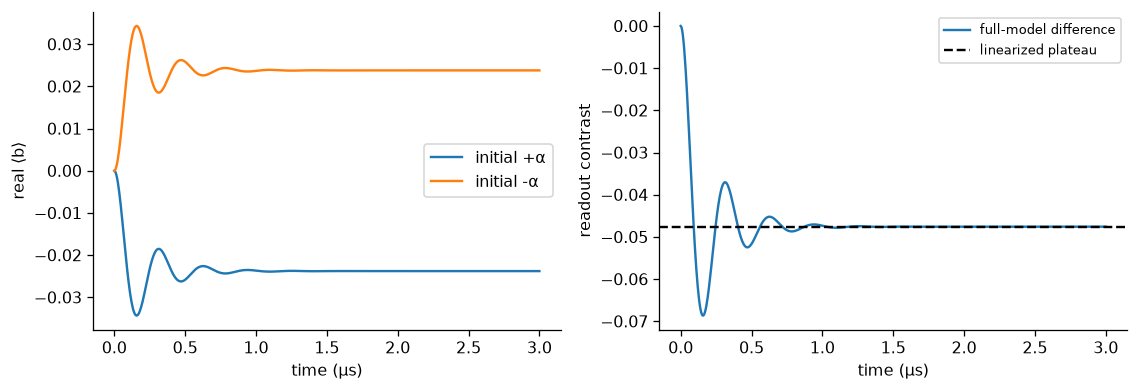

In [14]:
weak_drive = 0.1 * g2  # comfortably smaller than the exchange coupling
read_t = np.linspace(0, 3, 601)  # resolves the underdamped oscillation
read_plus = full_run(28, 6, read_t, seed=alpha, drive=weak_drive)
read_minus = full_run(28, 6, read_t, seed=-alpha, drive=weak_drive)
contrast = read_plus["e"][3] - read_minus["e"][3]  # common buffer offset cancels
linear_contrast = -weak_drive / (alpha * g2)  # twice the single-well displacement
plateau = np.mean(contrast[read_t > 2.0].real)
outside = np.flatnonzero(abs(contrast.real - plateau) > 0.02 * abs(plateau))
settling_time = read_t[outside[-1] + 1] if outside[-1] + 1 < len(read_t) else np.nan
print(f"contrast plateau {plateau:.6f}; linear estimate {linear_contrast:.6f}")
print(f"2% settling time within the 3 μs window: {settling_time:.3f} μs")
omega = 2 * g2 * alpha  # local memory-buffer exchange frequency
print(f"linearized ringing period: {2*np.pi/np.sqrt(omega**2-(kb/4)**2):.3f} μs")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(read_t, read_plus["e"][3].real, label="initial +α")
axes[0].plot(read_t, read_minus["e"][3].real, label="initial -α")
axes[0].set(xlabel="time (μs)", ylabel="real ⟨b⟩")
axes[0].legend()
axes[1].plot(read_t, contrast.real, label="full-model difference")
axes[1].axhline(linear_contrast, ls="--", color="black", label="linearized plateau")
axes[1].set(xlabel="time (μs)", ylabel="readout contrast")
axes[1].legend(fontsize=8)
finish_figure(fig, "12_buffer_readout")

2.4a — put the drive back into the circuit

one concrete implementation is a capacitive memory port:
$H_{\mathrm{port}}=2\epsilon_Z(t)\cos(\omega_a t+\theta)(a+a^\dagger)$.
in the rotating frame its resonant part is
$\epsilon_Z(t)(e^{i\theta}a+e^{-i\theta}a^\dagger)$; there are also terms
oscillating at $2\omega_a$. choosing $\theta=0$ gives the requested drive.
this is an explicit extra control port, just as the problem already permits a
separate capacitive buffer drive. it is not secretly another flux pump.

an alternative flux pump at $\omega_a$ has additional resonant cubic terms.
writing its amplitude as $\epsilon_r$, the first-order rotating-wave result is

$$E_J\epsilon_r\varphi_a\left[\left(1-\frac{\varphi_a^2}{2}
-\frac{\varphi_b^2}{2}\right)(a+a^\dagger)
-\frac{\varphi_a^2}{2}(a^\dagger a^2+a^{\dagger2}a)
-\varphi_b^2(a+a^\dagger)n_b\right].$$

this follows from the resonant part of $X_a^3$, which is
$3(a^\dagger a^2+a)+\mathrm{h.c.}$, and the dc part of $X_b^2=2n_b+1$.
stronger flux readout therefore does not scale a clean linear drive alone.
the numerical protocol below chooses the capacitive implementation to avoid
those specific resonant cubic readout terms.

there is a sign inconsistency worth making explicit in the supplied draft:
at its stated +π/2 differential bias, the cubic term of
$+2E_J\epsilon_p\cos(\omega_pt)\sin\varphi$ gives *negative* resonant g₂.
the quoted positive formula is its magnitude. reversing the pump phase gives
our positive-g₂ convention; the buffer-drive phase must be calibrated with it.
the workshop slide's opposite differential bias also reverses this sign.

for the stabilizing pump, the cubic rotating-wave term is the intended
$a^2b^\dagger+\mathrm{h.c.}$, but fifth and higher odd orders dress its fock-state
matrix elements. at fifth order the forward matrix element is multiplied by

$$1-\frac{\varphi_a^2}{6}(2n_a-1)-\frac{\varphi_b^2}{2}(n_b+1).$$

below i keep the *entire sine*, then retain exactly resonant matrix elements.
this checks the small-phase expansion without resolving GHz time steps. it
does not include second-order virtual off-resonant shifts, pump-induced changes
to dissipators, thermal noise, or a real measurement amplifier. those are
limitations, not effects this rotating-wave calculation has verified away.

In [15]:
wa, wb, ej = 2 * np.pi * np.array([4000.0, 4800.0, 40000.0])  # ghz converted to mhz, then angular units
phia, phib = 0.06, 0.3  # zero-point phase fluctuations from the circuit table
eps_p = 2 * g2 / (ej * phia**2 * phib)  # magnitude; use the pump phase discussed above
print(f"required pump amplitude = {eps_p:.8f} rad; pump frequency / 2π = {(2*wa-wb)/(2*np.pi):.1f} MHz")


def sine_exchange(na, nb, calibrate=True, order=None):
    aa = qt.tensor(qt.destroy(na + 8), qt.qeye(nb + 8))  # padding avoids boundary errors in the sine
    bb = qt.tensor(qt.qeye(na + 8), qt.destroy(nb + 8))
    phase = phia * (aa + aa.dag()) + phib * (bb + bb.dag())
    if order is None:
        da = qt.displace(na + 8, 1j * phia).full()[:na, :na]  # exp(i phi_a X_a)
        db = qt.displace(nb + 8, 1j * phib).full()[:nb, :nb]
        displacement = np.kron(da, db)  # commuting mode operators factorize exactly
        sine = (displacement - displacement.conj().T) / (2j)
    else:
        series = phase - phase**3 / 6  # cubic comparison
        if order >= 5:
            series = series + phase**5 / 120
        keep = np.array([i * (nb + 8) + j for i in range(na) for j in range(nb)])
        sine = series.full()[np.ix_(keep, keep)]  # crop only after expanding in the padded space
    energy = np.array([wa * i + wb * j for i in range(na) for j in range(nb)])
    resonant = np.isclose(abs(energy[:, None] - energy[None, :]), 2 * wa - wb, atol=1e-6, rtol=0)
    exchange = -ej * eps_p * sine * resonant  # minus = chosen π pump-phase shift; cos supplies 1/2
    raw_g = exchange[1, 2 * nb].real / np.sqrt(2)  # |2,0> -> |0,1> low-occupancy calibration
    if calibrate:
        exchange = exchange * g2 / raw_g  # separate a recalibratable g shift from number dependence
    return dq.asqarray(exchange, dims=(na, nb), layout=dq.dia), raw_g


exact_exchange, raw_g = sine_exchange(28, 6, calibrate=False)
cubic_exchange, _ = sine_exchange(28, 6, calibrate=False, order=3)
fifth_exchange, _ = sine_exchange(28, 6, calibrate=False, order=5)
entry_rows = []
for memory_n, buffer_n in [(2, 0), (5, 0), (10, 0), (5, 1), (10, 3)]:
    row, column = (memory_n - 2) * 6 + buffer_n + 1, memory_n * 6 + buffer_n
    cubic = dq.to_numpy(cubic_exchange)[row, column].real
    entry_rows.append({"initial memory n": memory_n, "initial buffer n": buffer_n,
                       "exact/cubic": dq.to_numpy(exact_exchange)[row, column].real / cubic,
                       "fifth/cubic": dq.to_numpy(fifth_exchange)[row, column].real / cubic})
table(pd.DataFrame(entry_rows), "circuit_matrix_elements")
print(f"uncalibrated low-occupancy coupling shift: {100*(raw_g/g2-1):.3f}%")

required pump amplitude = 0.03532407 rad; pump frequency / 2π = 3200.0 MHz


,initial memory n,initial buffer n,exact/cubic,fifth/cubic
0,2,0,0.954278,0.9532
1,5,0,0.950846,0.9496
2,10,0,0.945146,0.9436
3,5,1,0.908058,0.9046
4,10,3,0.821350,0.8086


uncalibrated low-occupancy coupling shift: -4.572%


2.4b — measure the contrast/error trade-off

increasing εz increases the coherent buffer separation but also perturbs the
protected manifold. the sweep uses α=1.2 so Γx remains independently resolvable;
it does not pretend these are the target-size rates. the physical-size pulse
comparison follows separately. all points use the same loss and exchange rates.

,drive/g2,contrast at 2.5–3 us,Γx,larger-cutoff Γx,relative cutoff change,spectral residual
0,0.00,0.000000,0.000600,0.000600,0.000421,7.168364e-15
1,0.05,0.040448,0.003158,0.003168,0.003270,1.372495e-13
2,0.10,0.079267,0.010920,0.010959,0.003552,1.755282e-12
3,0.20,0.145594,0.043618,0.043739,0.002768,2.813113e-11
4,0.40,0.192245,0.208040,0.207910,0.000625,1.112278e-09


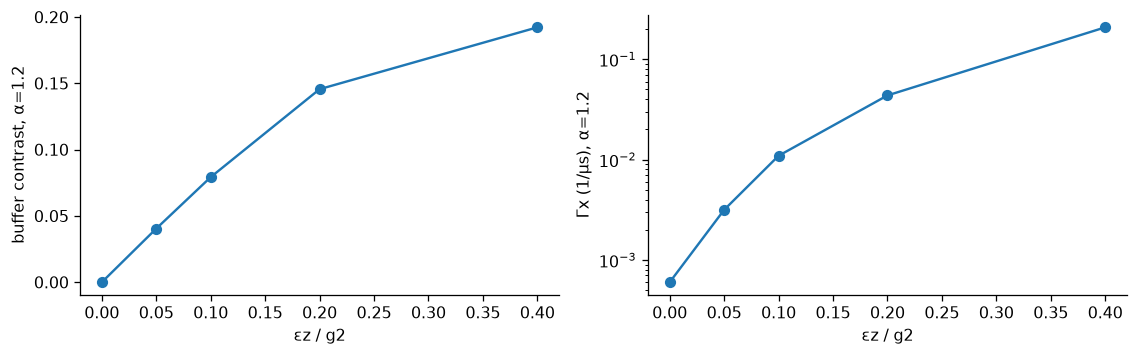

In [16]:
drive_rows = []
for fraction in [0.0, 0.05, 0.1, 0.2, 0.4]:
    drive = fraction * g2
    mode = slow_bit_mode(18, 4, 1.2, drive=drive)
    larger = slow_bit_mode(22, 5, 1.2, drive=drive)
    run = full_run(22, 5, np.linspace(0, 3, 301), amplitude=1.2, seed=1.2, drive=drive)
    contrast_here = 2 * abs(np.mean(run["e"][3, -51:].real))  # exact sign symmetry gives the other branch
    drive_rows.append({"drive/g2": fraction, "contrast at 2.5–3 us": contrast_here,
                       "Γx": mode["rate"], "larger-cutoff Γx": larger["rate"],
                       "relative cutoff change": abs(larger["rate"] / mode["rate"] - 1),
                       "spectral residual": mode["residual"]})
drive_table = pd.DataFrame(drive_rows)
table(drive_table, "dc_readout_tradeoff")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(drive_table["drive/g2"], drive_table["contrast at 2.5–3 us"], "o-")
axes[0].set(xlabel="εz / g2", ylabel="buffer contrast, α=1.2")
axes[1].semilogy(drive_table["drive/g2"], drive_table["Γx"], "o-")
axes[1].set(xlabel="εz / g2", ylabel="Γx (1/μs), α=1.2")
finish_figure(fig, "13_dc_tradeoff")

2.4c — an experiment: use the transient, then listen during ringdown

near either well the real buffer signal obeys
$\ddot b+(\kappa_b/2)\dot b+\Omega^2b=\mp\Omega\epsilon_Z(t)$,
where $\Omega=2g_2\alpha$. this is an underdamped filter, not an instantaneous
displacement. a receiver that averages a changing-sign signal can throw away
information. a matched filter weights the recorded quadrature by its predicted
time-dependent difference, including the passive ringdown after the drive ends.

i compare a constant drive, a short pulse with passive listening, and a smooth
resonant pulse. these are candidates, not assumed winners. they have the same
maximum memory-drive amplitude and the same total observation/recovery time.
a second comparison later rescales amplitudes to equal measured information.

for ideal homodyne detection,
$dY=2\sqrt{\eta\kappa_b}\mathrm{Re}\langle b\rangle dt+dW$.
assuming shot-noise-limited, approximately coherent output, define
$\mathcal I=\eta\kappa_b\int[\mathrm{Re}(b_+-b_-)]^2dt$.
then $\mathrm{SNR}^2=4\mathcal I$ (separation over one standard deviation) and
$P_{\mathrm{assignment}}\simeq\frac12\mathrm{erfc}(\sqrt{\mathcal I/2})$.
this is a mean-signal information proxy, not a stochastic-trajectory validation
of assignment error. it excludes excess output noise and amplifier effects.

a finite pulse has no stationary Γx. after the drive, i let stabilization recover
the state, then report the wrong orthogonal-codeword population and residual
leakage separately. i do not rename temporary displacement as a logical flip.

In [17]:
def pulse_run(na, nb, waveform, total=3.0, amplitude=alpha, corrected=False, sign=1, tolerance=2e-10):
    h, jumps, ops, a, b = two_mode(na, nb, amplitude)
    if corrected:
        exchange, _ = sine_exchange(na, nb, calibrate=True)  # include all resonant odd-phase orders
        h = exchange - g2 * amplitude**2 * (b + b.dag())
    h = h + dq.modulated(waveform, a + a.dag(), discontinuity_ts=[np.pi / omega, 1.5])  # known pulse edges
    times = np.linspace(0, total, int(total * 400) + 1)  # 2.5 ns output grid, independently of solver steps
    initial = dq.tensor(dq.coherent(na, sign * amplitude), dq.fock(nb, 0))
    run = evolve(h, jumps, initial, times, ops, (na, nb), rtol=100*tolerance, atol=tolerance)
    even = np.asarray(dq.to_numpy(cat_ket(na, amplitude, 1))).ravel()
    odd = np.asarray(dq.to_numpy(cat_ket(na, amplitude, -1))).ravel()
    wrong = (even - sign * odd) / np.sqrt(2)  # orthogonal logical basis; coherent wells only approximate it
    rho = run["rho"][-1]
    p_wrong = np.vdot(wrong, rho @ wrong).real
    in_code = np.vdot(even, rho @ even).real + np.vdot(odd, rho @ odd).real
    difference = 2 * run["e"][3].real  # opposite branch checked explicitly below
    information = kb * cumulative_trapezoid(difference**2, times, initial=0)  # eta=1; scale linearly for other efficiencies
    run.update({"wrong": p_wrong, "leakage": 1-in_code, "information": information,
                "box information": kb * np.trapezoid(difference, times)**2 / total})
    return run


def waveform_family(kind, peak, duration=1.5):
    if kind == "constant":
        return lambda t: jnp.where(t < duration, peak, 0.0)  # explicit discontinuity tested with tighter tolerance
    if kind == "short pulse":
        return lambda t: jnp.where(t < np.pi / omega, peak, 0.0)  # roughly half a local exchange cycle
    if kind == "resonant":
        return lambda t: jnp.where(t < duration, peak * jnp.sin(np.pi*t/duration)**2 * jnp.cos(omega*t), 0.0)
    raise ValueError(kind)

,pulse,peak limit/g2,matched information,unweighted information,wrong codeword,residual leakage,information/wrong
0,constant,0.5,1.445384,6.911788e-01,0.000697,0.000009,2073.547547
1,short pulse,0.5,0.242890,7.520205e-03,0.000083,0.000008,2912.367166
2,resonant,0.5,0.989814,4.039736e-07,0.000329,0.000008,3007.034413


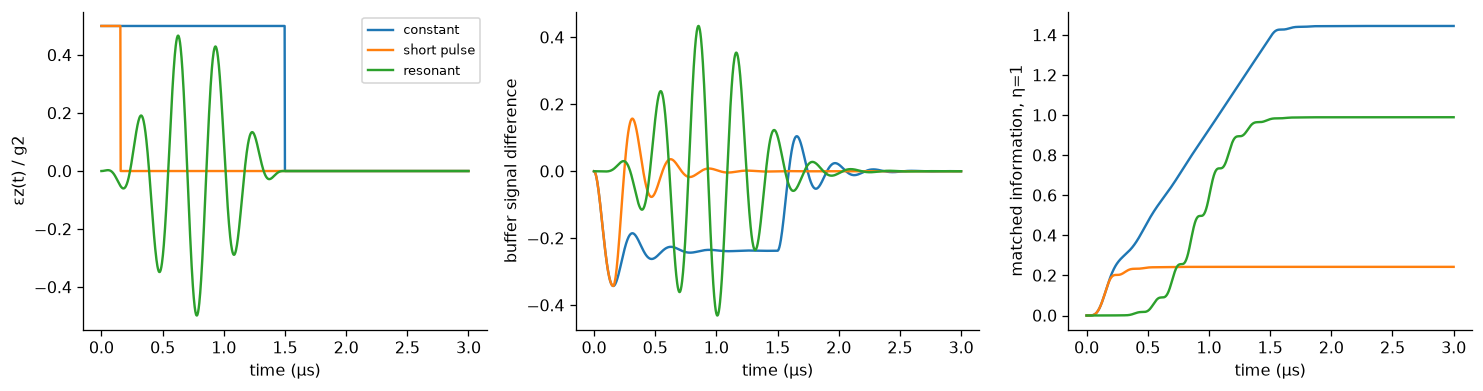

In [18]:
candidate_peak = 0.5 * g2  # explicit common hardware amplitude limit
candidate_runs = {}
candidate_rows = []
for kind in ["constant", "short pulse", "resonant"]:
    run = pulse_run(28, 6, waveform_family(kind, candidate_peak))
    candidate_runs[kind] = run
    candidate_rows.append({"pulse": kind, "peak limit/g2": 0.5, "matched information": run["information"][-1],
                           "unweighted information": run["box information"], "wrong codeword": run["wrong"],
                           "residual leakage": run["leakage"], "information/wrong": run["information"][-1]/run["wrong"]})
table(pd.DataFrame(candidate_rows), "pulse_candidates")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for kind, run in candidate_runs.items():
    waveform = waveform_family(kind, candidate_peak)
    axes[0].plot(run["t"], np.asarray(jax.vmap(waveform)(jnp.asarray(run["t"])))/g2, label=kind)
    axes[1].plot(run["t"], 2 * run["e"][3].real, label=kind)
    axes[2].plot(run["t"], run["information"], label=kind)
axes[0].set(ylabel="εz(t) / g2")
axes[1].set(ylabel="buffer signal difference")
axes[2].set(ylabel="matched information, η=1")
for axis in axes:
    axis.set(xlabel="time (μs)")
axes[0].legend(fontsize=8)
finish_figure(fig, "14_transient_pulse_candidates")

same peak is useful engineering context, but not a fair information/error
comparison by itself: the waveforms deliver different amounts of information.
next i match the two informative long pulses to the same measured $\mathcal I$,
keeping the same 3 μs total protocol and never exceeding the shared peak limit.
amplitude rescaling uses the quadratic small-signal prediction and then checks
the full nonlinear master equation again. no result is selected by ignoring
unsuccessful candidates.

In [19]:
target_information = 0.8 * min(candidate_runs[k]["information"][-1] for k in ["constant", "resonant"])
matched_runs = {}
matched_amplitudes = {}
for kind in ["constant", "resonant"]:
    peak = candidate_peak * np.sqrt(target_information / candidate_runs[kind]["information"][-1])
    for iteration in range(2):
        run = pulse_run(28, 6, waveform_family(kind, peak))
        if iteration == 0:
            peak *= np.sqrt(target_information / run["information"][-1])  # one nonlinear correction, then a fresh solve
    assert peak <= candidate_peak * (1+1e-8)
    assert abs(run["information"][-1]/target_information-1) < 0.01  # explicit 1% equal-information criterion
    matched_runs[kind] = run
    matched_amplitudes[kind] = peak
idle_pulse = pulse_run(28, 6, lambda t: 0.0 * t)  # same 3 μs, no readout drive
matched_rows = []
for kind, run in matched_runs.items():
    matched_rows.append({"pulse": kind, "peak/g2": matched_amplitudes[kind]/g2,
                         "information": run["information"][-1], "wrong codeword": run["wrong"],
                         "excess over idle": run["wrong"]-idle_pulse["wrong"], "leakage": run["leakage"],
                         "effective 2p/T": 2*run["wrong"]/3, "gaussian assignment estimate, eta=1": 0.5*erfc(np.sqrt(run["information"][-1]/2))})
matched_table = pd.DataFrame(matched_rows)
table(matched_table, "equal_information_comparison")
relative_reduction = 1 - matched_runs["resonant"]["wrong"] / matched_runs["constant"]["wrong"]
print(f"recovered wrong-codeword reduction at matched information: {100*relative_reduction:.2f}%")
print(f"idle wrong-codeword population: {idle_pulse['wrong']:.3e}")
print("2p/T is a protocol comparison, not a stationary Γx measurement.")
opposite_pulse = pulse_run(28, 6, waveform_family("resonant", matched_amplitudes["resonant"]), sign=-1)
sign_error = np.max(abs(opposite_pulse["e"][3].real + matched_runs["resonant"]["e"][3].real))
print(f"explicit opposite-codeword symmetry error: {sign_error:.3e}")
assert sign_error < 1e-6

,pulse,peak/g2,information,wrong codeword,excess over idle,leakage,effective 2p/T,"gaussian assignment estimate, eta=1"
0,constant,0.369756,0.791854,0.000317,0.000317,0.000008,0.000212,0.186770
1,resonant,0.446728,0.791866,0.000252,0.000252,0.000008,0.000168,0.186768


recovered wrong-codeword reduction at matched information: 20.43%
idle wrong-codeword population: 5.146e-07
2p/T is a protocol comparison, not a stationary Γx measurement.


explicit opposite-codeword symmetry error: 0.000e+00


2.4d — try to break the apparent improvement

readout starts near a well, so it does not need the same buffer cutoff as
vacuum inflation. that is a reason to test smaller cutoffs, not permission to
assume they work. the checks below vary the memory and buffer separately, then
increase both, tighten the solver, and add the calibrated sine-rwa correction.
frequency mistuning tests whether the result depends on hitting one exact number.
the carrier is still at ωa; these few-mhz envelope sidebands are far below GHz.

In [20]:
robust_rows = []
for label, na, nb, corrected, atol in [
    ("smaller memory", 24, 6, False, 2e-10),
    ("smaller buffer", 28, 4, False, 2e-10),
    ("larger cutoffs + tighter solver", 32, 8, False, 2e-11),
    ("calibrated full sine, rwa", 28, 6, True, 2e-10),
]:
    pair = {}
    for kind in ["constant", "resonant"]:
        run = pulse_run(na, nb, waveform_family(kind, matched_amplitudes[kind]), corrected=corrected, tolerance=atol)
        pair[kind] = run
        robust_rows.append({"check": label, "pulse": kind, "information": run["information"][-1],
                            "wrong codeword": run["wrong"], "leakage": run["leakage"],
                            "max memory tail": run["e"][5].real.max(), "max buffer tail": run["e"][6].real.max(),
                            "min reduced eigenvalue": checks(run)["min eigenvalue"]})
    print(f"{label}: information ratios to nominal = "
          f"{pair['constant']['information'][-1]/target_information:.3f}, "
          f"{pair['resonant']['information'][-1]/target_information:.3f}; "
          f"wrong-codeword ratio resonant/constant = {pair['resonant']['wrong']/pair['constant']['wrong']:.3f}")
robust_table = pd.DataFrame(robust_rows)
table(robust_table, "readout_robustness")
mistuning_rows = []
for factor in [0.9, 1.0, 1.1]:
    envelope = lambda t: jnp.where(t < 1.5, matched_amplitudes["resonant"] * jnp.sin(np.pi*t/1.5)**2 * jnp.cos(factor*omega*t), 0.0)
    run = pulse_run(28, 6, envelope)
    mistuning_rows.append({"envelope frequency/nominal": factor, "information": run["information"][-1],
                           "wrong codeword": run["wrong"], "information/wrong": run["information"][-1]/run["wrong"]})
table(pd.DataFrame(mistuning_rows), "envelope_mistuning")

smaller memory: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.794


smaller buffer: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.864


larger cutoffs + tighter solver: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.794


calibrated full sine, rwa: information ratios to nominal = 1.010, 0.969; wrong-codeword ratio resonant/constant = 0.641


,check,pulse,information,wrong codeword,leakage,max memory tail,max buffer tail,min reduced eigenvalue
0,smaller memory,constant,0.791853,0.000318,0.000009,1.090045e-07,0.000013,-1.675527e-08
1,smaller memory,resonant,0.791867,0.000253,0.000008,1.250873e-07,0.000023,-1.279383e-08
2,smaller buffer,constant,0.791968,0.000383,0.000009,1.419440e-08,0.000176,-5.077094e-08
3,smaller buffer,resonant,0.791716,0.000331,0.000008,1.160672e-08,0.000366,-3.969575e-08
4,larger cutoffs + tighter solver,constant,0.791859,0.000307,0.000008,2.040036e-08,0.000002,-7.047004e-08
5,larger cutoffs + tighter solver,resonant,0.791814,0.000244,0.000008,3.658362e-10,0.000003,-2.089669e-09
6,"calibrated full sine, rwa",constant,0.799959,0.000354,0.000026,6.421473e-09,0.000020,-1.266514e-08
7,"calibrated full sine, rwa",resonant,0.767679,0.000227,0.000025,5.971562e-09,0.000031,-1.278330e-08


,envelope frequency/nominal,information,wrong codeword,information/wrong
0,0.9,0.789361,0.000257,3069.778996
1,1.0,0.791866,0.000252,3136.763619
2,1.1,0.672932,0.000206,3261.493663


what this does and does not establish

the proposal is an underdamped, sideband-shaped readout with a matched temporal
receiver. the local transfer function motivates its frequency; the two-mode
nonlinear simulations decide whether it helps. the primary comparison is
information per recovered logical-bit disturbance, not peak buffer amplitude.
no new nonlinearity or extra stabilization pump is assumed. an iq-capable memory
drive and time-resolved homodyne processing are required.

the drive is still disturbing: a favorable comparison against constant readout
does not mean the idle Γx was preserved. neither does it prove a high-fidelity
single-shot hardware measurement. the reported gaussian assignment estimate
is only a shot-noise proxy, and the example information budget is modest.
a further experiment should simulate conditional measurement records, include
realistic detection efficiency and output noise, and optimize a target error
budget with the full calibrated circuit and bath model.

the full-sine check is first order in pump amplitude and rotating-wave only.
at the supplied illustrative circuit parameters, neglecting the higher odd
powers without calibration would already shift the low-occupancy coupling by
several percent. the off-resonant linear pump term should first be handled by
a displacement/calibration; virtual shifts and transformed dissipation need a
controlled effective-model calculation, not an unsupported blanket 'rwa is fine'.

the introductory reference had a small negative density eigenvalue at the
explicit integrator's tolerance. inspect the printed diagnostic: this numerical
violation is tiny compared with the introductory observable tolerance, but
would be unacceptable as an unreported floor for rare-error claims. readout
has its own tighter-tolerance and cutoff checks above.

this is a numerically tested proposal within the stated model, not a claim
that no one has used resonant readout or matched filtering before.

In [21]:
summary = {"versions": versions, "time_unit": "microsecond", "rates": "expectation-value decay rates",
           "bit_suppression_exponent": float(-log_slope), "phase_slope": float(phase_slope),
           "predicted_phase_slope": float(2*ka), "matched_information": float(target_information),
           "wrong_codeword_reduction_fraction": float(relative_reduction),
           "constant_wrong_codeword": float(matched_runs["constant"]["wrong"]),
           "resonant_wrong_codeword": float(matched_runs["resonant"]["wrong"]),
           "caveat": "finite-pulse ideal-model benchmark; not a stationary rate or hardware measurement fidelity"}
(artifacts / "summary.json").write_text(json.dumps(summary, indent=2))  # actual results only
display(pd.Series({key: value for key, value in summary.items() if key != "versions"}))
print("the plots, tables, and this summary were generated by the cells above.")

time_unit                                                                  microsecond
rates                                                    expectation-value decay rates
bit_suppression_exponent                                                      2.954541
phase_slope                                                                   0.116684
predicted_phase_slope                                                         0.116867
matched_information                                                           0.791851
wrong_codeword_reduction_fraction                                             0.204336
constant_wrong_codeword                                                       0.000317
resonant_wrong_codeword                                                       0.000252
caveat                               finite-pulse ideal-model benchmark; not a stat...
dtype: object

the plots, tables, and this summary were generated by the cells above.


sources and further checks

- supplied `duquantum_2026_challenge_prompt-v4.md` and `2026-10-24 DuQuantun Hackathon.pdf`:
  task definitions, circuit parameters, sign conventions, and workshop context.
- [réglade, bocquet et al., 2024](https://arxiv.org/abs/2307.06617): the two-mode
  experiment, its nonadiabatic regime, circuit derivation, and buffer readout.
- [dubovitskii, 2025](https://arxiv.org/abs/2407.17299): second-order bit-flip
  mechanisms; its event-rate convention differs by a factor of two here.
- [guillaud, cohen, mirrahimi, lecture notes](https://arxiv.org/abs/2203.03222):
  dissipative cats and the protected-manifold viewpoint.
- [gautier et al., zeno gates](https://doi.org/10.1103/PRXQuantum.4.040316):
  nonadiabatic control and information leakage; gate protection is not the
  same objective as making leaked information useful for readout.
- [carde et al., flux-pump degradation](https://arxiv.org/abs/2410.00975): why
  circuit-level corrections can involve dissipators, not just extra hamiltonian terms.
- [rousseau et al., moon cats](https://arxiv.org/abs/2502.07892): squeezing is
  an existing stabilization strategy, not an original discovery of this notebook.
- [dynamiqs solver documentation](https://www.dynamiqs.org/stable/python_api/integrators/mesolve.html)
  and [official challenge tutorials](https://github.com/YQuantum-2026/Alice-Bob-Challenge/tree/main/challenge/resources).

the prior psiteratops submission supplied as context studies a different drift
optimization problem. its results are not evidence for this readout proposal.

one last numerical check — resolve the inflation reference's precision floor

the large (40,16) reference is expensive, and its earlier explicit-solver run
had small negative density eigenvalues. here the same full model is rerun with
1000 times tighter absolute tolerance. this distinguishes genuine fock tails
from numerical noise. the signed tail plot intentionally shows negative values
instead of silently putting them on a positive logarithmic axis.

this also estimates the coherence decay time from the *inflation data itself*.
it is a late-time exponential envelope fit, not a claim that coherence suddenly
disappears at one particular time. optional cached arrays are keyed to the
actual matrices, time grid, package versions, and tolerances.

tighter reference density checks: {'trace error': np.float64(3.1086244689504383e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.3060592396864901e-09)}
absolute changes in peak/end photons: 2.314e-08, 1.357e-07
inflated-cat late parity e-fold time: 1.9438 μs


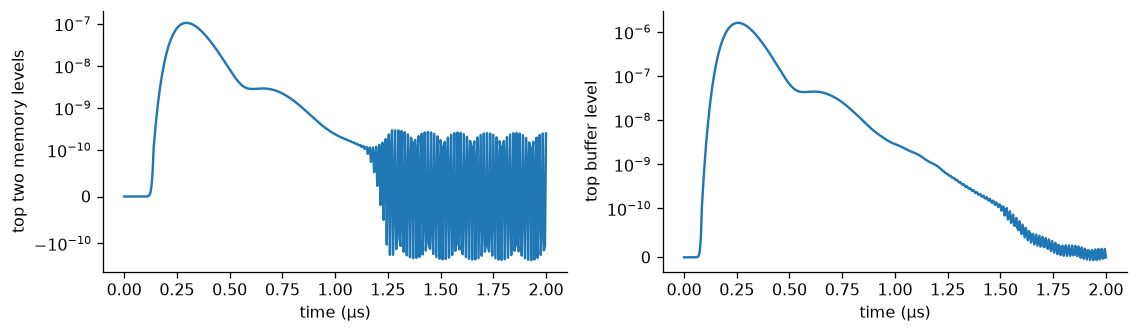

all small-cat bit rates change by <1% at larger cutoffs: True
constant larger-cutoff changes: information 5.845e-06, wrong-codeword 3.179e-02
resonant larger-cutoff changes: information 6.611e-05, wrong-codeword 3.322e-02
even charging all residual leakage as a wrong bit, resonant error bound = 0.000260678
constant-drive wrong-codeword population for comparison = 0.000317278


In [22]:
tight_t = np.linspace(0, 2, 401)  # identical output times to the inflation reference
tight_inflation = full_run(40, 16, tight_t, rtol=2e-11, atol=2e-13)
tight_checks = checks(tight_inflation)
old_cutoffs = pd.read_csv(artifacts / "cutoff_convergence.csv")  # generated earlier in this notebook
old_reference = old_cutoffs.query("na == 40 and nb == 16").iloc[0]
peak_change = abs(tight_inflation["e"][0].real.max() - old_reference["peak n"])
end_change = abs(tight_inflation["e"][0, -1].real - old_reference["final n"])
print("tighter reference density checks:", tight_checks)
print(f"absolute changes in peak/end photons: {peak_change:.3e}, {end_change:.3e}")
assert peak_change < 1e-4 and end_change < 1e-4  # far tighter than the declared 0.2% cutoff tolerance
assert tight_checks["min eigenvalue"] > -1e-7  # now explicitly check the density positivity floor
late = tight_t >= 0.8  # after the main inflation transient
parity_envelope = tight_inflation["e"][4].real - np.exp(-2*alpha**2)
coherence_slope, _ = np.polyfit(tight_t[late], np.log(parity_envelope[late]), 1)
print(f"inflated-cat late parity e-fold time: {-1/coherence_slope:.4f} μs")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for axis, index, label in zip(axes, [5, 6], ["top two memory levels", "top buffer level"]):
    axis.plot(tight_t, tight_inflation["e"][index].real)
    axis.set_yscale("symlog", linthresh=1e-10)  # preserve the sign of precision-scale residuals
    axis.set(xlabel="time (μs)", ylabel=label)
finish_figure(fig, "15_tight_reference_tails")
bit_validation = pd.read_csv(artifacts / "bit_flip_rates.csv")  # the already-computed results, not a new fit
robust_validation = pd.read_csv(artifacts / "readout_robustness.csv")
matched_validation = pd.read_csv(artifacts / "equal_information_comparison.csv").set_index("pulse")
bit_checks_pass = bool((bit_validation["cutoff relative change"] < 0.01).all())
print(f"all small-cat bit rates change by <1% at larger cutoffs: {bit_checks_pass}")
assert bit_checks_pass
large_readout = robust_validation[robust_validation["check"] == "larger cutoffs + tighter solver"]
for _, row in large_readout.iterrows():
    nominal = matched_validation.loc[row["pulse"]]
    print(f"{row['pulse']} larger-cutoff changes: information {abs(row['information']/nominal['information']-1):.3e}, "
          f"wrong-codeword {abs(row['wrong codeword']/nominal['wrong codeword']-1):.3e}")
    assert abs(row["wrong codeword"]/nominal["wrong codeword"]-1) < 0.04  # this small protocol diagnostic is stable to 4%
worst_resonant = matched_validation.loc["resonant", "wrong codeword"] + matched_validation.loc["resonant", "leakage"]
print(f"even charging all residual leakage as a wrong bit, resonant error bound = {worst_resonant:.6g}")
print(f"constant-drive wrong-codeword population for comparison = {matched_validation.loc['constant', 'wrong codeword']:.6g}")

2.4 extension — choose the ending, then calculate the pulse

the question here is narrower than 'undo a measurement': can a drive leave a
useful emitted signal while bringing the *motion* back near its starting point?
this cannot recover coherence that the measured bit information has destroyed.
reset-shaped measurement pulses already exist in other architectures, e.g.
[jerger et al.](https://arxiv.org/abs/2406.04891). the test here is their usefulness
for this nonlinear dissipative cat, not a claim that pulse cleanup is new.

put y = im(a - alpha), x = re(b), and omega = 2 g2 alpha near the positive well.
to first order, y' = -ka y/2 - omega x - u and x' = omega y - kb x/2.
near the other well the same drive gives the same y and opposite x. therefore
one open-loop pulse can satisfy the endpoint conditions for either stored bit.
the tiny loss-induced shift of the real well is omitted in this design model;
it is present in the full quantum simulation used to judge the result.

expand u in smooth functions sin²(pi t/d) cos(m pi t/d). integrate each one's
response, then find combinations with x(d)=y(d)=0 using a matrix nullspace.
within that space maximize emitted signal energy per drive energy using a
generalized eigenvalue problem. the robust version also cancels the first
derivative of the endpoint with respect to the exchange frequency.
this is a linear design hypothesis, not a proof of quantum recovery.

In [ ]:
from scipy.integrate import solve_ivp  # only the inexpensive two-variable design model

design_duration = 1.5  # all candidates still get the same 3 microseconds total
design_modes = 15  # a fixed smooth basis, not hundreds of freely fitted samples
design_peak_limit = 0.5 * g2  # same amplitude limit as the earlier experiment
extension_target = 0.79  # chosen before testing new pulses; not high-fidelity readout
extension_criteria = {"information relative": 0.01, "wrong relative": 0.01,
                      "wrong absolute": 2e-6, "negative eigenvalue": 1e-7,
                      "assignment absolute": 0.03}  # keep these unchanged if a test fails


def linear_pulse_response(duration, frequency_factor=1.0):
    grid = np.linspace(0, duration, 1501)  # resolves the fastest basis function
    harmonics = np.arange(design_modes)  # the zero-frequency member is included
    def basis(t):
        return np.sin(np.pi*t/duration)**2 * np.cos(harmonics*np.pi*t/duration)
    frequency = 2*g2*alpha*frequency_factor
    matrix = np.array([[-ka/2, -frequency], [frequency, -kb/2]])
    def rhs(t, state):
        motion = state.reshape(2, design_modes)
        forcing = np.stack([-basis(t), np.zeros(design_modes)])
        return (matrix @ motion + forcing).ravel()
    solution = solve_ivp(rhs, (0, duration), np.zeros(2*design_modes), t_eval=grid,
                         rtol=2e-10, atol=2e-12)  # design accuracy, separate from the quantum solver
    assert solution.success
    response = solution.y.reshape(2, design_modes, -1).transpose(2, 0, 1)
    basis_values = np.array([basis(t) for t in grid])
    return grid, basis_values, response


def calculate_closed_pulse(robust=False):
    grid, basis_values, response = linear_pulse_response(design_duration)
    endpoint = response[-1]  # maps coefficients to the two residual quadratures
    constraints = endpoint
    if robust:
        _, _, lower = linear_pulse_response(design_duration, 0.99)
        _, _, upper = linear_pulse_response(design_duration, 1.01)
        derivative = (upper[-1] - lower[-1]) / 0.02
        constraints = np.vstack([endpoint, derivative])  # first-order robustness, not a guarantee over a large interval
    null = la.null_space(constraints)  # every vector in this subspace closes the linear trajectory
    signal_gram = 4*kb*np.trapezoid(response[:, 1, :, None]*response[:, 1, None, :], grid, axis=0)
    energy_gram = np.trapezoid(basis_values[:, :, None]*basis_values[:, None, :], grid, axis=0)
    values, vectors = la.eigh(null.T @ signal_gram @ null, null.T @ energy_gram @ null)
    coefficients = null @ vectors[:, -1]  # greatest information proxy per integrated drive energy
    fine_grid = np.linspace(0, design_duration, 30001)
    fine_basis = np.sin(np.pi*fine_grid[:, None]/design_duration)**2 * np.cos(np.arange(design_modes)*np.pi*fine_grid[:, None]/design_duration)
    coefficients /= 1.0001*np.max(abs(fine_basis @ coefficients))  # a small safety margin below the amplitude cap
    return {"kind": "closed robust" if robust else "closed nominal", "duration": design_duration,
            "coefficients": coefficients.tolist(), "peak": float(design_peak_limit)}


def extension_waveform(spec):
    duration, peak = spec["duration"], spec["peak"]
    kind = spec["kind"]
    coefficients = jnp.asarray(spec.get("coefficients", [0.0]))
    def envelope(t):
        if kind.startswith("closed"):
            value = jnp.sin(jnp.pi*t/duration)**2 * jnp.sum(coefficients*jnp.cos(jnp.arange(len(coefficients))*jnp.pi*t/duration))
        elif kind == "resonant":
            value = jnp.sin(jnp.pi*t/duration)**2 * jnp.cos(2*g2*alpha*t)
        elif kind == "flat":
            edge = 0.02  # finite 20 ns ramps; an ideal step would have infinite bandwidth
            value = jnp.sin(jnp.pi/2*jnp.minimum(jnp.minimum(t, duration-t)/edge, 1.0))**2
        else:
            value = 0.0*t  # idle reference
        return jnp.where((t >= 0) & (t < duration), peak*value, 0.0)
    return envelope


closed_specs = [calculate_closed_pulse(False), calculate_closed_pulse(True)]
linear_rows = []
for spec in closed_specs:
    for factor in [0.95, 1.0, 1.05]:
        grid, basis_values, response = linear_pulse_response(spec["duration"], factor)
        coefficients = spec["peak"]*np.asarray(spec["coefficients"])
        endpoint = response[-1] @ coefficients
        linear_rows.append({"pulse": spec["kind"], "exchange factor": factor,
                            "residual motion squared": float(endpoint @ endpoint)})
table(pd.DataFrame(linear_rows), "closed_linear_endpoints")
assert max(row["residual motion squared"] for row in linear_rows if row["exchange factor"] == 1.0) < 1e-16
print("fixed acceptance criteria:", extension_criteria)

now let the full quantum model disagree with the design, if it needs to.
the training cutoff is (24,6); the larger cutoffs below are held-out tests.
a fixed target information of 0.79 corresponds to roughly 19% assignment error
in the earlier ideal gaussian estimate. this is a modest-information benchmark,
not a demonstrated high-fidelity measurement. a candidate unable to reach the
target under the amplitude cap is marked infeasible, not quietly given more power.
the flat-drive baseline is tuned over three durations, with finite edge ramps.

In [ ]:
def extension_run(spec, na=24, nb=6, tolerance=2e-12, coupling_factor=1.0, corrected=False, sign=1):
    h, jumps, ops, a, b = two_mode(na, nb, coupling=g2*coupling_factor)
    if corrected:
        exchange, _ = sine_exchange(na, nb, calibrate=True)
        h = exchange - g2*alpha**2*(b+b.dag())  # same calibrated circuit correction as above
    times = np.linspace(0, 3, 601)  # saved grid; adaptive integration uses much smaller internal steps
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
    base_path = run_key(h, jumps, initial, times, ops, 100*tolerance, tolerance)
    digest = hashlib.sha256((base_path.stem + json.dumps(spec, sort_keys=True) + "closed-pulse-v1").encode()).hexdigest()
    path = base_path.with_name(digest + ".npz")  # include the entire pulse and the actual model in the cache key
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            run = {name: saved[name] for name in ["t", "e", "rho"]}
            run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
    else:
        edges = sorted(set([0.02, spec["duration"]-0.02, spec["duration"]]))
        driven = h + dq.modulated(extension_waveform(spec), a+a.dag(), discontinuity_ts=edges)
        run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=100*tolerance, atol=tolerance)
        save_run(path, run)
    even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()
    odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
    wrong = (even-sign*odd)/np.sqrt(2)
    wrong_t = np.einsum("i,tij,j->t", wrong.conj(), run["rho"], wrong).real
    in_code = sum(np.einsum("i,tij,j->t", cat.conj(), run["rho"], cat).real for cat in [even, odd])
    run.update({"wrong": float(wrong_t[-1]), "leakage": float(1-in_code[-1]),
                "wrong trace": wrong_t, "leakage trace": 1-in_code,
                "information": float(4*kb*np.trapezoid(run["e"][3].real**2, times)),
                "spec": dict(spec), "checks": checks(run)})
    return run


def match_extension(spec, target=extension_target, na=24, nb=6):
    trial = dict(spec, peak=float(design_peak_limit))
    run = extension_run(trial, na, nb)
    if run["information"] < target*(1-extension_criteria["information relative"]):
        return run, False  # do not violate the hardware limit to force a favorable comparison
    for _ in range(4):
        trial["peak"] *= float(np.sqrt(target/run["information"]))
        if trial["peak"] > design_peak_limit:
            return run, False
        run = extension_run(trial, na, nb)
        if abs(run["information"]/target-1) < 0.002:
            return run, True
    return run, abs(run["information"]/target-1) < extension_criteria["information relative"]


training_specs = [{"kind": "flat", "duration": duration, "peak": float(design_peak_limit)} for duration in [0.75, 1.5, 2.25]]
training_specs += [{"kind": "resonant", "duration": 1.5, "peak": float(design_peak_limit)}, *closed_specs]
training_runs, training_rows = {}, []
for spec in training_specs:
    label = f"{spec['kind']} {spec['duration']:g} us"
    run, feasible = match_extension(spec)
    training_runs[label] = run
    training_rows.append({"pulse": label, "feasible": feasible, "information": run["information"],
                          "peak/g2": run["spec"]["peak"]/g2, "wrong": run["wrong"], "leakage": run["leakage"],
                          "wrong + leakage": run["wrong"]+run["leakage"]})
    print(label, training_rows[-1], flush=True)
training_table = pd.DataFrame(training_rows)
table(training_table, "closed_training")

the selection rule counts leakage as failure, rather than hiding it behind a
small wrong-codeword population. the new pulse must beat the existing resonant
waveform too, not just the flat drive. a small difference may be unresolved.
readiness is a separate metric: after the drive ends, has the information
reached 99% of the target and does leakage stay below a declared threshold?
i show three thresholds (1e-3, 1e-4, 1e-5), because there is no universal hardware
definition of 'ready'. this is an unconditional-state diagnostic, not a bound
on every individual measurement trajectory.

In [ ]:
feasible_training = training_table[training_table["feasible"]].copy()
flat_label = feasible_training[feasible_training["pulse"].str.startswith("flat")].sort_values("wrong + leakage").iloc[0]["pulse"]
closed_label = feasible_training[feasible_training["pulse"].str.startswith("closed")].sort_values("wrong + leakage").iloc[0]["pulse"]
selected_specs = {"flat": training_runs[flat_label]["spec"],
                  "resonant": training_runs["resonant 1.5 us"]["spec"],
                  "closed": training_runs[closed_label]["spec"]}  # freeze before looking at larger cutoffs
print("selected on the training cutoff:", flat_label, "and", closed_label)


def ready_time(run, leakage_limit):
    information_t = 4*kb*cumulative_trapezoid(run["e"][3].real**2, run["t"], initial=0)
    good = (run["leakage trace"] <= leakage_limit) & (information_t >= 0.99*extension_target)
    stays_good = np.logical_and.accumulate(good[::-1])[::-1]  # do not count a brief crossing during ringing
    indices = np.flatnonzero(stays_good & (run["t"] >= run["spec"]["duration"]))
    return float(run["t"][indices[0]]) if len(indices) else np.nan


validation_runs, validation_rows, readiness_rows = {}, [], []
for label, spec in selected_specs.items():
    for na, nb in [(24, 6), (32, 8), (36, 10)]:
        run = extension_run(spec, na, nb)
        validation_runs[(label, na, nb)] = run
        validation_rows.append({"pulse": label, "na": na, "nb": nb, "information": run["information"],
                                "wrong": run["wrong"], "leakage": run["leakage"],
                                "wrong + leakage": run["wrong"]+run["leakage"],
                                "max memory tail": float(run["e"][5].real.max()),
                                "max buffer tail": float(run["e"][6].real.max()), **run["checks"]})
        print("held-out check", label, na, nb, validation_rows[-1], flush=True)
    reference, previous = validation_runs[(label, 36, 10)], validation_runs[(label, 32, 8)]
    wrong_change = abs(reference["wrong"]-previous["wrong"])
    passed = (wrong_change < max(extension_criteria["wrong absolute"], extension_criteria["wrong relative"]*abs(reference["wrong"]))
              and abs(reference["information"]/previous["information"]-1) < extension_criteria["information relative"]
              and reference["checks"]["min eigenvalue"] > -extension_criteria["negative eigenvalue"])
    print(f"{label}: held-out numerical criterion passed = {passed}; wrong absolute change = {wrong_change:.3e}", flush=True)
    for threshold in [1e-3, 1e-4, 1e-5]:
        readiness_rows.append({"pulse": label, "leakage threshold": threshold,
                               "ready time us": ready_time(reference, threshold)})
table(pd.DataFrame(validation_rows), "closed_validation")
table(pd.DataFrame(readiness_rows), "closed_readiness")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for label, spec in selected_specs.items():
    run = validation_runs[(label, 36, 10)]
    axes[0].plot(run["t"], jax.vmap(extension_waveform(spec))(jnp.asarray(run["t"]))/g2, label=label)
    axes[1].plot(run["t"], 4*kb*cumulative_trapezoid(run["e"][3].real**2, run["t"], initial=0), label=label)
    axes[2].plot(run["t"], run["wrong trace"]+run["leakage trace"], label=label)
axes[0].set(ylabel="memory drive / g2", xlabel="time (μs)")
axes[1].set(ylabel="information proxy", xlabel="time (μs)")
axes[2].set(ylabel="wrong codeword + leakage", xlabel="time (μs)", yscale="log")
axes[0].legend()
finish_figure(fig, "16_closed_pulse_recovery")

these are stress tests of the frozen pulse, without reoptimizing its shape.
a coupling change also changes the stabilizing pump consistently to keep alpha
fixed. this is a calibrated-g uncertainty test, not a claim to cover every
possible independent pump error. the circuit test retains the resonant sine
corrections derived above; it still omits counter-rotating and transformed-bath
effects. information can change in a stress test, so it is printed alongside
damage rather than silently calling the comparison equal-information.

In [ ]:
stress_rows = []
for label in ["flat", "closed"]:
    for factor, corrected, condition in [(0.95, False, "coupling -5%"), (1.05, False, "coupling +5%"),
                                          (1.0, True, "calibrated resonant sine")]:
        run = extension_run(selected_specs[label], 32, 8, coupling_factor=factor, corrected=corrected)
        stress_rows.append({"pulse": label, "condition": condition, "information": run["information"],
                            "wrong": run["wrong"], "leakage": run["leakage"],
                            "ready time at 1e-4 us": ready_time(run, 1e-4)})
        print("stress test", stress_rows[-1], flush=True)
table(pd.DataFrame(stress_rows), "closed_stress_tests")

noisy readout, including quantum backaction

rather than adding noise to the mean curve, simulate homodyne quantum
trajectories with [dynamiqs' diffusive solver](https://www.dynamiqs.org/stable/python_api/integrators/dssesolve.html).
both loss channels are unraveled to keep the state a small vector. only the
buffer record is given to the classifier; discarding the memory-channel record
gives the correct buffer-record marginal for an unobserved memory bath.
[the solver documentation](https://www.dynamiqs.org/stable/python_api/integrators/dsmesolve.html)
explicitly supports this record-only construction. no feedback uses the hidden
channel. the trajectories are not conditional memory states for a buffer-only
observer; interpreting them that way would be incorrect.

the receiver uses a fixed matched filter from the deterministic simulation,
with a zero threshold fixed by branch symmetry, not fitted to the test records.
this is a specified practical classifier, not necessarily the optimal receiver.
time-averaged currents must be multiplied by their bin widths when integrating.
efficiency is one here; detector loss, bandwidth and amplifier noise are not
magically included. the ideal-output gaussian prediction is only a comparison.

In [ ]:
def trajectory_batch(spec, sign, seed, count=128, dt=0.0001, na=24, nb=6, map_normalization=False):
    h, jumps, ops, a, b = two_mode(na, nb)
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
    times = np.linspace(0, 3, 601)  # 5 ns record bins; dt is the finer stochastic integration step
    base_path = run_key(h, jumps, initial, times, [ops[0]], dt, dt)
    settings = {"pulse": spec, "seed": seed, "count": count, "dt": dt,
                "method": "Rouchon1-normalized-v1" if map_normalization else "Rouchon1-ket-normalized-v1"}
    digest = hashlib.sha256((base_path.stem+json.dumps(settings, sort_keys=True)).encode()).hexdigest()
    path = base_path.with_name("records-"+digest+".npz")
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            return {key: saved[key] for key in saved.files}
    driven = h+dq.modulated(extension_waveform(spec), a+a.dag())  # smooth edges are resolved by the fixed step
    keys = jax.random.split(jax.random.key(seed), count)  # independent seeds are recorded for reproducibility
    started = time.monotonic()
    result = dq.dssesolve(driven, jumps, initial, times, keys, exp_ops=[ops[0]],
                         method=dq.method.Rouchon1(dt=dt, normalize=map_normalization), save_states=False)
    # both variants normalize each ket; the expensive option also corrects the discrete Kraus map
    records = np.asarray(result.measurements)[:, 0, :]  # buffer channel only; do not leak the memory record
    final_n = np.asarray(result.expects)[:, 0, -1].real
    assert np.isfinite(records).all() and np.isfinite(final_n).all()
    output = {"t": times, "records": records, "final_n": final_n}
    np.savez_compressed(path, **output)
    print(f"{spec['kind']} sign {sign:+d}: {count} trajectories, dt={dt:g}, ({na},{nb}), {time.monotonic()-started:.1f}s", flush=True)
    return output


def wilson_interval(errors, count):
    z = 1.959963984540054  # two-sided 95% binomial score interval, not sqrt(p) error bars
    p = errors/count
    center = (p+z*z/(2*count))/(1+z*z/count)
    half = z*np.sqrt(p*(1-p)/count+z*z/(4*count*count))/(1+z*z/count)
    return float(center-half), float(center+half)


def score_records(batch, template):
    times = batch["t"]
    weight = 2*np.sqrt(kb)*np.interp(times, template["t"], template["e"][3].real)
    weight = (weight[:-1]+weight[1:])/2  # bin-average approximation; bins are short compared with ringing
    widths = np.diff(times)
    normalization = np.sqrt(np.sum(weight*weight*widths))
    return batch["records"] @ (weight*widths) / normalization

In [ ]:
record_rows, record_samples = [], {}
for label, spec in selected_specs.items():
    template = validation_runs[(label, 24, 6)]  # deterministic filter; none of the test records trains it
    for sign in [1, -1]:
        scores, final_numbers = [], []
        for repeat in range(2):
            seed = 20261024 + 1000*(sign < 0) + repeat  # common random numbers across pulses, independent between bits/batches
            batch = trajectory_batch(spec, sign, seed, count=512)
            scores.extend(score_records(batch, template))
            final_numbers.extend(batch["final_n"])
        scores, final_numbers = np.asarray(scores), np.asarray(final_numbers)
        errors = sign*scores <= 0
        low, high = wilson_interval(int(errors.sum()), len(errors))
        record_samples[(label, sign)] = {"scores": scores, "errors": errors, "final n": final_numbers}
        record_rows.append({"pulse": label, "initial bit sign": sign, "shots": len(errors),
                            "errors": int(errors.sum()), "assignment error": float(errors.mean()),
                            "95% low": low, "95% high": high, "score mean": float(scores.mean()),
                            "score standard deviation": float(scores.std(ddof=1)),
                            "final n mean": float(final_numbers.mean()),
                            "final n standard error": float(final_numbers.std(ddof=1)/np.sqrt(len(final_numbers)))})
        print("noisy readout", record_rows[-1], flush=True)
record_table = pd.DataFrame(record_rows)
table(record_table, "closed_noisy_readout")

assignment_rows = []
for label in selected_specs:
    errors = np.concatenate([record_samples[(label, sign)]["errors"] for sign in [1, -1]])
    low, high = wilson_interval(int(errors.sum()), len(errors))
    run = validation_runs[(label, 36, 10)]
    assignment_rows.append({"pulse": label, "shots": len(errors), "assignment error": float(errors.mean()),
                            "95% low": low, "95% high": high,
                            "gaussian mean-signal prediction": float(0.5*erfc(np.sqrt(run["information"]/2))),
                            "wrong": run["wrong"], "leakage": run["leakage"],
                            "wrong + leakage": run["wrong"]+run["leakage"]})
assignment_table = pd.DataFrame(assignment_rows)
table(assignment_table, "closed_assignment_summary")

comparison_rows = []
for baseline in ["flat", "resonant"]:
    differences = np.concatenate([record_samples[("closed", sign)]["errors"].astype(float)
                                  - record_samples[(baseline, sign)]["errors"].astype(float) for sign in [1, -1]])
    half = 1.96*differences.std(ddof=1)/np.sqrt(len(differences))  # paired interval, since the pulses share random seeds
    low, high = differences.mean()-half, differences.mean()+half
    comparison_rows.append({"comparison": "closed minus "+baseline, "assignment difference": differences.mean(),
                            "95% low": low, "95% high": high,
                            "within +/-3 percentage points": bool(low > -0.03 and high < 0.03)})
table(pd.DataFrame(comparison_rows), "closed_assignment_equivalence")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for _, row in assignment_table.iterrows():
    label = row["pulse"]
    numerical_change = abs(row["wrong + leakage"] - sum(validation_runs[(label, 32, 8)][key] for key in ["wrong", "leakage"]))
    axes[0].errorbar(row["assignment error"], row["wrong + leakage"],
                    xerr=[[row["assignment error"]-row["95% low"]], [row["95% high"]-row["assignment error"]]],
                    yerr=numerical_change, fmt="o", capsize=3, label=label)
    for sign, style in [(1, "-"), (-1, "--")]:
        axes[1].hist(record_samples[(label, sign)]["scores"], bins=np.linspace(-4, 4, 41),
                     density=True, histtype="step", linestyle=style, label=f"{label}, {sign:+d}")
axes[0].set(xlabel="measured assignment error (95% interval)", ylabel="wrong codeword + leakage")
axes[0].legend()
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="fixed matched-filter score", ylabel="record density")
axes[1].legend(fontsize=7, ncol=2)
finish_figure(fig, "17_noisy_readout_tradeoff")

the stochastic integrator is first order. normalized kets keep trajectories
well behaved, but that is not evidence of time-step convergence. the checks
below halve the integration step and increase the fock cutoffs independently.
they use new records, never the records used to choose the pulse. the smaller
validation samples have wider confidence intervals: 'inconclusive' is a valid
outcome, not a reason to loosen the declared three-percentage-point criterion.
rare bit-flip probabilities are taken from the deterministic density matrix,
not estimated by counting a handful of flips in this limited trajectory sample.

In [ ]:
record_check_rows = []
for label in ["flat", "closed"]:
    spec = selected_specs[label]
    for condition, dt, na, nb, normalized in [("half timestep", 0.00005, 24, 6, False),
                                               ("larger cutoffs", 0.0001, 32, 8, False),
                                               ("normalized discrete map", 0.0002, 24, 6, True)]:
        errors, aligned_scores, final_numbers = [], [], []
        template = validation_runs[(label, na, nb)]
        for sign in [1, -1]:
            seed = 30261024+1000*(sign < 0)+["half timestep", "larger cutoffs", "normalized discrete map"].index(condition)
            batch = trajectory_batch(spec, sign, seed, count=256, dt=dt, na=na, nb=nb, map_normalization=normalized)
            scores = score_records(batch, template)
            errors.extend(sign*scores <= 0)
            aligned_scores.extend(sign*scores)
            final_numbers.extend(batch["final_n"])
        errors, aligned_scores, final_numbers = np.asarray(errors), np.asarray(aligned_scores), np.asarray(final_numbers)
        low, high = wilson_interval(int(errors.sum()), len(errors))
        reference = assignment_table.set_index("pulse").loc[label]
        difference = errors.mean()-reference["assignment error"]
        half = 1.96*np.sqrt(errors.mean()*(1-errors.mean())/len(errors)
                            + reference["assignment error"]*(1-reference["assignment error"])/reference["shots"])
        record_check_rows.append({"pulse": label, "check": condition, "shots": len(errors),
                                  "assignment error": errors.mean(), "95% low": low, "95% high": high,
                                  "difference from main": difference, "difference 95% halfwidth": half,
                                  "within +/-3 percentage points": bool(abs(difference)+half < 0.03),
                                  "aligned score mean": aligned_scores.mean(),
                                  "score mean standard error": aligned_scores.std(ddof=1)/np.sqrt(len(errors)),
                                  "deterministic predicted score": np.sqrt(template["information"]),
                                  "final n mean": final_numbers.mean(),
                                  "deterministic final n": template["e"][0, -1].real})
        print("record validation", record_check_rows[-1], flush=True)
table(pd.DataFrame(record_check_rows), "closed_record_validation")